# Лабораторная работа № 2. Консолидация разнородных источников: CSV + Excel + JSON → SQLite → аналитика

**Направление:** 38.04.05 «Бизнес-информатика», магистратура  
**Среда:** один ноутбук Google Colab, без Docker и без внешней СУБД · до 10 баллов за основную часть

## Цель

Собрать данные из трёх источников разного формата, провести аудит и очистку, загрузить результат в локальную реляционную базу SQLite, рассчитать выручку по субъектам и довести результат до управленческих выводов.

## Задачи

1. Прочитать три источника: справочник субъектов (CSV), события с объёмом (Excel) и цены по событиям (JSON).
2. Провести **аудит качества** по шести измерениям: полнота, уникальность, согласованность, валидность, целостность, точность.
3. Очистить данные с ведением **журнала изменений** и карантина: ни одна строка не исчезает молча.
4. Спроектировать схему в SQLite: первичные и внешние ключи, ограничения `CHECK`, индексы.
5. Показать и устранить эффект **fan-out при соединении один-ко-многим** — главную причину завышенной выручки в отчётности.
6. Сверить расчёт на SQL и в pandas, провести аналитику (концентрация, Парето и ABC, сезонность, структура по классам) и сформулировать выводы.
7. **Дополнительно, по желанию:** выгрузить витрину в BigQuery и повторить расчёт (необязательный раздел; основная работа полностью выполняется в SQLite).

## Чем эта работа отличается от версии с Docker и PostgreSQL

| | Прежняя схема | Текущая схема |
|---|---|---|
| Инфраструктура | Docker Compose, контейнер PostgreSQL, Jupyter в контейнере | один ноутбук в Colab |
| СУБД | PostgreSQL 15 на порту 5432 | SQLite: база — один файл рядом с ноутбуком |
| Запуск | установка Docker, `docker compose up`, проброс портов | «Выполнить все» |
| Что теряем | ничего существенного для учебной задачи | — |
| Что приобретаем | — | воспроизводимость, отсутствие проблем с портами и правами |

SQL остаётся тем же: `CREATE TABLE`, ключи, `JOIN`, `GROUP BY`, оконные конструкции и CTE. Отличия SQLite от PostgreSQL, важные для работы, разобраны в теоретическом блоке.

## Что сдаётся

Ноутбук **с выводами ячеек**, файл базы `*.sqlite` и выгрузка витрины, опубликованные в личном репозитории GitHub; в LMS сдаётся ссылка на репозиторий.

## Как выполнять работу

1. **Файл → Сохранить копию на Диске.**
2. В шаге 1 укажите номер варианта, выданный преподавателем. От него зависят предметная область, объём данных и набор дефектов.
3. Выполняйте ячейки сверху вниз: генерация источников → аудит → очистка → SQLite → аналитика → выводы.
4. Перед каждым шагом дано методическое обоснование, после — интерпретация результата. Места с пометкой `TODO` дописываете вы.
5. Раздел BigQuery необязателен. Он включается флагом `ENABLE_BIGQUERY` и требует аккаунта Google Cloud; без него работа выполняется полностью.
6. Перед сдачей запустите самопроверку: должно быть «Выполнено: 11 из 11».

**Важно про данные.** Источники генерируются кодом и намеренно содержат дефекты: дубликаты, пропуски, два формата даты, числа строками с валютой, отрицательные цены, записи с несуществующим внешним ключом. Это не ошибка генератора — это предмет работы. Задача аналитика не в том, чтобы получить красивое число, а в том, чтобы знать, из чего оно посчитано и что было отброшено.

## Теоретический блок

### 1. Консолидация: что это и где ломается

Консолидация — приведение данных из разных источников к единой модели, пригодной для анализа. Типовой конвейер:

```
Извлечение (Extract) → Профилирование → Очистка → Сопоставление ключей → Загрузка (Load) → Витрина → Анализ
```

Три формата, с которыми вы работаете, ведут себя по-разному:

| Формат | Что гарантирует | Типичные проблемы |
|---|---|---|
| **CSV** | ничего, кроме текста | кодировка, разделитель, отсутствие типов: `007` превращается в `7`, а `2025-03-17` — в дату не всегда |
| **Excel** | типы ячеек и автоформатирование | «умное» приведение типов, скрытые пробелы, даты как числа, разные листы и объединённые ячейки |
| **JSON** | структуру и типы | вложенность, разный набор полей у записей, числа строками |

Общее правило: **читать всё как текст и приводить типы явно**. В работе так и сделано — `dtype=str` при чтении, затем контролируемое преобразование.

### 2. Шесть измерений качества данных

| Измерение | Вопрос | Как проверяется в работе |
|---|---|---|
| Полнота | всё ли на месте | доля непустых значений по каждой колонке |
| Уникальность | нет ли дублей | дубликаты строк и повторы ключей |
| Согласованность | одинаково ли записано | два формата даты, числа с валютой и пробелами |
| Валидность | попадает ли в допустимый диапазон | отрицательные цены, нулевой объём |
| Целостность | сходятся ли ссылки между таблицами | события с `entity_id`, которого нет в справочнике |
| Точность | похоже ли на правду | выбросы по правилу 3×IQR |

Принципиальное правило работы: **пропуск не равен нулю**. Замена `NaN` на 0 занижает средние и портит медианы; строка с непригодным значением отправляется в карантин, а не удаляется молча.

### 3. Ключи, кардинальность и fan-out — центральная идея работы

У связи между таблицами есть кардинальность:

* **1 : 1** — одной записи соответствует одна;
* **1 : N** — у события несколько ценовых строк (разные классы);
* **N : M** — требует таблицы-связки.

Если соединить три таблицы «в лоб», строка события повторится столько раз, сколько у него ценовых строк. Это и есть **fan-out**: сумма объёма и выручки завышается кратно.

```
events (1 строка, 180 единиц)      prices (3 строки: 5 000, 12 000, 25 000)
        └──────────── JOIN ────────────┘
результат: 3 строки по 180 единиц → SUM(volume) = 540 вместо 180
```

Правильный порядок действий: **сначала свернуть подчинённую таблицу до уровня родителя (агрегировать цены по событию), потом соединять**. В работе оба варианта считаются и сравниваются численно — вы увидите коэффициент завышения на своих данных.

Формула расчёта после свёртки:

$$
Revenue_{entity} = \sum_{e \in events(entity)} volume_e \cdot \overline{price}_e,
\qquad
\overline{price}_e = \frac{1}{n_e}\sum_{i=1}^{n_e} price_{e,i}
$$

Среднее здесь — упрощение. Если известно количество проданных единиц по каждому классу, корректнее взвешенное среднее; это вынесено в задание со звёздочкой.

### 4. SQLite: что важно знать

SQLite — встраиваемая СУБД: вся база это один файл, сервер не нужен. Именно поэтому она заменяет здесь PostgreSQL в контейнере.

| Особенность | Следствие для работы |
|---|---|
| Внешние ключи **выключены** по умолчанию | обязательно `PRAGMA foreign_keys = ON;` в начале сессии |
| Динамическая типизация (type affinity) | в колонку `INTEGER` можно записать текст: типы контролирует ваш код и `CHECK` |
| Нет отдельного типа `DATE` | даты хранятся строками `YYYY-MM-DD` — формат, который корректно сортируется |
| Нет `TRUE/FALSE` | используйте 0 и 1 |
| Одна запись за раз, читателей много | для учебной задачи и витрин на миллионы строк этого достаточно |
| Поддерживает CTE и оконные функции | `WITH ... AS`, `ROW_NUMBER() OVER (...)` работают как в PostgreSQL |

Чего в SQLite нет по сравнению с PostgreSQL: серверного доступа по сети, ролей и прав, материализованных представлений, параллельной записи, богатых типов (`JSONB`, `ARRAY`, геоданные). Когда эти возможности понадобятся, переносится тот же SQL — меняется строка подключения.

### 5. Три уровня хранения: когда что выбирать

| | SQLite | PostgreSQL | BigQuery |
|---|---|---|---|
| Развёртывание | файл, ноль настройки | сервер или контейнер | облачный сервис |
| Объём | до сотен миллионов строк на одной машине | терабайты | петабайты |
| Модель оплаты | бесплатно | инфраструктура | за объём прочитанных данных |
| Параллельная запись | одна | много | пакетная загрузка |
| Где уместна | прототип, учебная работа, витрина одного аналитика | продуктовая база, многопользовательский доступ | аналитика на больших объёмах, редкие тяжёлые запросы |

Учебная витрина этой работы — десятки тысяч строк. Для неё SQLite избыточно достаточен, и это тоже профессиональный вывод: инструмент выбирается под объём и режим доступа, а не по громкости названия.

### Шаг 1. Окружение и параметры варианта

**Методическое обоснование.** Colab — одноразовая среда: нужные библиотеки проверяются и при необходимости доустанавливаются, рабочая папка создаётся заново. Номер варианта задаёт предметную область, объём генерации и уровень дефектов — от него детерминированно зависят все дальнейшие числа, поэтому результат воспроизводим.

In [ ]:
#@title Шаг 1. Окружение и параметры варианта { display-mode: "form" }
VARIANT = 2                  #@param {type:"slider", min:1, max:30, step:1}
ENABLE_BIGQUERY = False      #@param {type:"boolean"}
RANDOM_CHECK = True          #@param {type:"boolean"}

import importlib, json, math, os, re, sqlite3, subprocess, sys, textwrap, warnings
from datetime import datetime, timedelta
from pathlib import Path

def ensure(pkg, module=None):
    try:
        importlib.import_module(module or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
        importlib.invalidate_caches()

for pkg, mod in [("pandas", "pandas"), ("numpy", "numpy"), ("openpyxl", "openpyxl"),
                 ("matplotlib", "matplotlib"), ("seaborn", "seaborn")]:
    ensure(pkg, mod)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 11})
pd.set_option("display.width", 170, "display.max_columns", 50, "display.float_format", "{:,.2f}".format)

WORK = Path("/content/pw2" if Path("/content").exists() else "pw2_work")
DATA = WORK / "data"
DATA.mkdir(parents=True, exist_ok=True)
DB_PATH = WORK / f"consolidation_variant_{VARIANT}.sqlite"

def todo(step):
    raise NotImplementedError(f"Не выполнен шаг TODO {step} — допишите код в отмеченном месте")

def nf(x, digits=0):
    """Число с пробелом-разделителем разрядов: 1 234 567."""
    if x is None or (isinstance(x, float) and math.isnan(x)):
        return "—"
    return f"{x:,.{digits}f}".replace(",", " ")

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"sqlite3 {sqlite3.sqlite_version}")
print(f"Рабочая папка: {WORK}")

Python 3.12.14 | pandas 3.0.6 | numpy 2.5.4 | sqlite3 3.53.1
Рабочая папка: pw2_work


In [ ]:
#@title Шаг 1.1. Конфигурация варианта { display-mode: "form" }
VARIANTS = [
{
"id": 1,
"domain": "Авиаперевозки",
"parent": "Авиакомпании",
"event": "Рейсы",
"price": "Билеты",
"unit": "пассажиров",
"cls": "класс билета",
"analytics": "Сезонность перевозок: в каком месяце выручка максимальна и какие компании её формируют",
"seed": 1007,
"n_parents": 9,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Авиакомпании — CSV, Рейсы — XLSX, Билеты — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Авиакомпании»"
},
{
"id": 2,
"domain": "Розничная сеть",
"parent": "Магазины",
"event": "Чеки",
"price": "Позиции чека",
"unit": "единиц товара",
"cls": "категория товара",
"analytics": "ABC-анализ магазинов: какие точки дают 80 % выручки",
"seed": 1014,
"n_parents": 10,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Магазины — CSV, Чеки — XLSX, Позиции чека — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Магазины»"
},
{
"id": 3,
"domain": "Логистика",
"parent": "Перевозчики",
"event": "Отгрузки",
"price": "Тарифы",
"unit": "паллет",
"cls": "тип тарифа",
"analytics": "Загрузка перевозчиков: связь объёма и средней ставки",
"seed": 1021,
"n_parents": 11,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Перевозчики — CSV, Отгрузки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Перевозчики»"
},
{
"id": 4,
"domain": "Телеком",
"parent": "Операторы",
"event": "Сессии связи",
"price": "Тарификация",
"unit": "минут",
"cls": "тарифный план",
"analytics": "Доля тарифных планов в выручке и средний чек сессии",
"seed": 1028,
"n_parents": 12,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Операторы — CSV, Сессии связи — XLSX, Тарификация — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы»"
},
{
"id": 5,
"domain": "Банковский ритейл",
"parent": "Отделения",
"event": "Операции",
"price": "Комиссии",
"unit": "транзакций",
"cls": "тип комиссии",
"analytics": "Эффективность отделений: выручка на одну операцию",
"seed": 1035,
"n_parents": 8,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Отделения — CSV, Операции — XLSX, Комиссии — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Отделения»"
},
{
"id": 6,
"domain": "Гостиничный бизнес",
"parent": "Отели",
"event": "Бронирования",
"price": "Тарифы номеров",
"unit": "ночей",
"cls": "категория номера",
"analytics": "Сезонность загрузки и вклад категорий номеров",
"seed": 1042,
"n_parents": 9,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Отели — CSV, Бронирования — XLSX, Тарифы номеров — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Отели»"
},
{
"id": 7,
"domain": "Образовательные услуги",
"parent": "Центры",
"event": "Группы",
"price": "Стоимость обучения",
"unit": "слушателей",
"cls": "формат обучения",
"analytics": "Выручка на слушателя и сравнение форматов",
"seed": 1049,
"n_parents": 10,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Центры — CSV, Группы — XLSX, Стоимость обучения — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Центры»"
},
{
"id": 8,
"domain": "Медицинские клиники",
"parent": "Клиники",
"event": "Приёмы",
"price": "Прейскурант",
"unit": "пациентов",
"cls": "вид услуги",
"analytics": "Структура выручки по видам услуг и загрузка клиник",
"seed": 1056,
"n_parents": 11,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Клиники — CSV, Приёмы — XLSX, Прейскурант — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Клиники»"
},
{
"id": 9,
"domain": "Энергосбыт",
"parent": "Сбытовые компании",
"event": "Поставки",
"price": "Тарифы",
"unit": "МВт·ч",
"cls": "категория потребителя",
"analytics": "Концентрация выручки по категориям потребителей",
"seed": 1063,
"n_parents": 12,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Сбытовые компании — CSV, Поставки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сбытовые компании»"
},
{
"id": 10,
"domain": "Маркетплейс",
"parent": "Продавцы",
"event": "Заказы",
"price": "Цены товаров",
"unit": "единиц",
"cls": "категория товара",
"analytics": "Топ продавцов и доля категорий в обороте",
"seed": 1070,
"n_parents": 8,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Продавцы — CSV, Заказы — XLSX, Цены товаров — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Продавцы»"
},
{
"id": 11,
"domain": "Общественный транспорт",
"parent": "Перевозчики",
"event": "Маршруты-рейсы",
"price": "Тарифы проезда",
"unit": "пассажиров",
"cls": "тип билета",
"analytics": "Выручка по типам билетов и пиковые месяцы",
"seed": 1077,
"n_parents": 9,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Перевозчики — CSV, Маршруты-рейсы — XLSX, Тарифы проезда — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Перевозчики»"
},
{
"id": 12,
"domain": "Страхование",
"parent": "Агентства",
"event": "Договоры",
"price": "Тарифные ставки",
"unit": "объектов",
"cls": "вид страхования",
"analytics": "Средняя премия по видам страхования и вклад агентств",
"seed": 1084,
"n_parents": 10,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Агентства — CSV, Договоры — XLSX, Тарифные ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Агентства»"
},
{
"id": 13,
"domain": "Грузовые ж/д перевозки",
"parent": "Операторы вагонов",
"event": "Отправки",
"price": "Ставки",
"unit": "тонн",
"cls": "род груза",
"analytics": "Доходность по родам груза и сезонность отправок",
"seed": 1091,
"n_parents": 11,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Операторы вагонов — CSV, Отправки — XLSX, Ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы вагонов»"
},
{
"id": 14,
"domain": "Общепит",
"parent": "Рестораны",
"event": "Заказы",
"price": "Цены блюд",
"unit": "порций",
"cls": "категория меню",
"analytics": "Средний чек и вклад категорий меню",
"seed": 1098,
"n_parents": 12,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Рестораны — CSV, Заказы — XLSX, Цены блюд — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Рестораны»"
},
{
"id": 15,
"domain": "Фитнес-сети",
"parent": "Клубы",
"event": "Визиты и покупки",
"price": "Прайс услуг",
"unit": "услуг",
"cls": "тип абонемента",
"analytics": "Выручка на клуб и структура абонементов",
"seed": 1105,
"n_parents": 8,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Клубы — CSV, Визиты и покупки — XLSX, Прайс услуг — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Клубы»"
},
{
"id": 16,
"domain": "Аренда спецтехники",
"parent": "Парки техники",
"event": "Смены аренды",
"price": "Ставки аренды",
"unit": "машино-часов",
"cls": "тип техники",
"analytics": "Утилизация парка и доходность типов техники",
"seed": 1112,
"n_parents": 9,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Парки техники — CSV, Смены аренды — XLSX, Ставки аренды — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Парки техники»"
},
{
"id": 17,
"domain": "Курьерская доставка",
"parent": "Службы доставки",
"event": "Доставки",
"price": "Тарифы",
"unit": "посылок",
"cls": "скорость доставки",
"analytics": "Доля экспресс-доставки в выручке",
"seed": 1119,
"n_parents": 10,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Службы доставки — CSV, Доставки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Службы доставки»"
},
{
"id": 18,
"domain": "Оптовая торговля",
"parent": "Дистрибьюторы",
"event": "Поставки",
"price": "Прайс-листы",
"unit": "коробов",
"cls": "товарная группа",
"analytics": "Парето по товарным группам и вклад дистрибьюторов",
"seed": 1126,
"n_parents": 11,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Дистрибьюторы — CSV, Поставки — XLSX, Прайс-листы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Дистрибьюторы»"
},
{
"id": 19,
"domain": "Автосервис",
"parent": "Сервисные центры",
"event": "Заказ-наряды",
"price": "Прейскурант работ",
"unit": "нормо-часов",
"cls": "вид работ",
"analytics": "Выручка по видам работ и загрузка центров",
"seed": 1133,
"n_parents": 12,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Сервисные центры — CSV, Заказ-наряды — XLSX, Прейскурант работ — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сервисные центры»"
},
{
"id": 20,
"domain": "Цифровые подписки",
"parent": "Сервисы",
"event": "Подписки",
"price": "Тарифные планы",
"unit": "подписчиков",
"cls": "план подписки",
"analytics": "Структура подписной базы и выручка на подписчика",
"seed": 1140,
"n_parents": 8,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Сервисы — CSV, Подписки — XLSX, Тарифные планы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сервисы»"
},
{
"id": 21,
"domain": "Сельхозпроизводство",
"parent": "Хозяйства",
"event": "Партии отгрузки",
"price": "Закупочные цены",
"unit": "тонн",
"cls": "культура",
"analytics": "Доходность культур и сезонность отгрузок",
"seed": 1147,
"n_parents": 9,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Хозяйства — CSV, Партии отгрузки — XLSX, Закупочные цены — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Хозяйства»"
},
{
"id": 22,
"domain": "Строительный ритейл",
"parent": "Гипермаркеты",
"event": "Продажи",
"price": "Цены материалов",
"unit": "единиц",
"cls": "группа материалов",
"analytics": "Сезонность продаж и вклад групп материалов",
"seed": 1154,
"n_parents": 10,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Гипермаркеты — CSV, Продажи — XLSX, Цены материалов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Гипермаркеты»"
},
{
"id": 23,
"domain": "Морские перевозки",
"parent": "Судоходные линии",
"event": "Рейсы судов",
"price": "Фрахтовые ставки",
"unit": "TEU",
"cls": "тип контейнера",
"analytics": "Доходность линий и структура по типам контейнеров",
"seed": 1161,
"n_parents": 11,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Судоходные линии — CSV, Рейсы судов — XLSX, Фрахтовые ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Судоходные линии»"
},
{
"id": 24,
"domain": "Аптечные сети",
"parent": "Аптеки",
"event": "Продажи",
"price": "Цены препаратов",
"unit": "упаковок",
"cls": "группа препаратов",
"analytics": "Вклад товарных групп и сравнение точек",
"seed": 1168,
"n_parents": 12,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Аптеки — CSV, Продажи — XLSX, Цены препаратов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Аптеки»"
},
{
"id": 25,
"domain": "Кинотеатры",
"parent": "Кинотеатры",
"event": "Сеансы",
"price": "Цены билетов",
"unit": "зрителей",
"cls": "тип сеанса",
"analytics": "Заполняемость залов и выручка по типам сеансов",
"seed": 1175,
"n_parents": 8,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Кинотеатры — CSV, Сеансы — XLSX, Цены билетов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Кинотеатры»"
},
{
"id": 26,
"domain": "Промышленное производство",
"parent": "Заводы",
"event": "Партии продукции",
"price": "Отпускные цены",
"unit": "тонн",
"cls": "марка продукции",
"analytics": "Вклад марок продукции и сезонность отгрузок",
"seed": 1182,
"n_parents": 9,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Заводы — CSV, Партии продукции — XLSX, Отпускные цены — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Заводы»"
},
{
"id": 27,
"domain": "Рекламные площадки",
"parent": "Площадки",
"event": "Кампании",
"price": "Ставки размещения",
"unit": "показов (тыс.)",
"cls": "формат размещения",
"analytics": "Доходность форматов и концентрация выручки",
"seed": 1189,
"n_parents": 10,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Площадки — CSV, Кампании — XLSX, Ставки размещения — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Площадки»"
},
{
"id": 28,
"domain": "ЖКХ",
"parent": "Управляющие компании",
"event": "Начисления",
"price": "Тарифы услуг",
"unit": "объектов",
"cls": "вид услуги",
"analytics": "Структура начислений и сравнение управляющих компаний",
"seed": 1196,
"n_parents": 11,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Управляющие компании — CSV, Начисления — XLSX, Тарифы услуг — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Управляющие компании»"
},
{
"id": 29,
"domain": "Каршеринг",
"parent": "Операторы",
"event": "Поездки",
"price": "Тарифы поездок",
"unit": "минут",
"cls": "класс автомобиля",
"analytics": "Выручка на поездку и вклад классов автомобилей",
"seed": 1203,
"n_parents": 12,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Операторы — CSV, Поездки — XLSX, Тарифы поездок — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы»"
},
{
"id": 30,
"domain": "Авиаперевозки (эталон преподавателя)",
"parent": "Авиакомпании",
"event": "Рейсы",
"price": "Билеты",
"unit": "пассажиров",
"cls": "класс билета",
"analytics": "Полный разбор: качество данных, fan-out при JOIN, сезонность, концентрация выручки",
"seed": 1210,
"n_parents": 8,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Авиакомпании — CSV, Рейсы — XLSX, Билеты — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Авиакомпании»"
}
]

def variant_config(v=None):
    v = VARIANT if v is None else int(v)
    found = [x for x in VARIANTS if x["id"] == v]
    if not found:
        raise ValueError("Номер варианта должен быть от 1 до 30")
    return found[0]

CFG = variant_config()
print(f"Вариант {CFG['id']} — {CFG['domain']}")
print(textwrap.fill(CFG["task"], 104))
print(f"\nCSV  : {CFG['parent']}        (справочник субъектов)")
print(f"XLSX : {CFG['event']}          (события, объём в единицах: {CFG['unit']})")
print(f"JSON : {CFG['price']}          (цены, разрез: {CFG['cls']})")
print(f"\nОбъём генерации: субъектов {CFG['n_parents']}, событий {nf(CFG['n_events'])}, "
      f"уровень дефектов {'★' * CFG['defect_level']}")
print(textwrap.fill("Аналитическая задача: " + CFG["analytics"], 104))

Вариант 2 — Розничная сеть
Консолидировать три источника (Магазины — CSV, Чеки — XLSX, Позиции чека — JSON), провести аудит
качества, загрузить в SQLite и рассчитать выручку по субъектам «Магазины»

CSV  : Магазины        (справочник субъектов)
XLSX : Чеки          (события, объём в единицах: единиц товара)
JSON : Позиции чека          (цены, разрез: категория товара)

Объём генерации: субъектов 10, событий 4 000, уровень дефектов ★★★
Аналитическая задача: ABC-анализ магазинов: какие точки дают 80 % выручки


**Интерпретация.** Убедитесь, что версия pandas и SQLite вывелись, а рабочая папка создана. Номер варианта определяет всё дальнейшее: если вы его измените, перезапустите ноутбук целиком, иначе данные и выводы будут из разных вариантов.

### Шаг 2. Генерация трёх источников

**Методическое обоснование.** В реальном проекте источники приходят от разных владельцев: бухгалтерия присылает Excel, ИТ-система выгружает JSON, справочник ведётся в CSV. Мы воспроизводим эту ситуацию, включая типичные дефекты: расхождение форматов дат, числа с валютой в текстовом поле, дубликаты, битые внешние ключи. Дефекты внесены осознанно и детерминированно — при проверке преподаватель знает, что именно вы должны были найти.

In [ ]:
#@title Шаг 2. Генерация трёх источников: CSV, XLSX, JSON { display-mode: "form" }
# Данные генерируются детерминированно от номера варианта: у каждого студента свои числа,
# но одинаковая структура. В данные намеренно внесены дефекты — их предстоит найти на шаге 3.
def generate_sources(cfg, out_dir=DATA):
    rng = np.random.default_rng(cfg["seed"])
    lvl = cfg["defect_level"]

    # ---------- 1. Справочник субъектов (CSV) --------------------------------------
    regions = ["Москва", "Санкт-Петербург", "Новосибирск", "Екатеринбург", "Казань",
               "Краснодар", "Самара", "Пермь", "Ростов-на-Дону", "Уфа", "Тюмень", "Омск"]
    n = cfg["n_parents"]
    cities = list(rng.choice(regions, n, replace=False))
    parents = pd.DataFrame({
        "entity_id": [f"E{i:03d}" for i in range(1, n + 1)],
        "entity_name": [f"{cfg['parent']} «{city}»" for city in cities],
        "region": cities,                      # регион совпадает с городом в названии
        "founded_year": rng.integers(1990, 2021, n),
    })
    # дефекты справочника: дубль строки, «грязное» имя, пропуск в регионе
    parents.loc[len(parents)] = parents.iloc[1].tolist()                       # полный дубликат
    parents.loc[2, "entity_name"] = "  " + parents.loc[2, "entity_name"].upper() + " "
    if lvl >= 2:
        parents.loc[3, "region"] = None
    parents.to_csv(out_dir / "entities.csv", index=False, encoding="utf-8")

    # ---------- 2. События с объёмом (XLSX) ----------------------------------------
    m = cfg["n_events"]
    start = datetime(2025, 1, 1)
    event_ids = [f"EV{i:06d}" for i in range(1, m + 1)]
    entity_ids = rng.choice(parents["entity_id"].iloc[:n].to_numpy(), m,
                            p=np.linspace(2.2, 0.6, n) / np.linspace(2.2, 0.6, n).sum())
    day_offsets = rng.integers(0, 365, m)
    # сезонность: летние и декабрьские месяцы нагружены сильнее
    season_boost = rng.random(m)
    dates = [start + timedelta(days=int(d)) for d in day_offsets]
    base_volume = rng.integers(60, 320, m)
    volume = np.where([d.month in (6, 7, 8, 12) for d in dates],
                      (base_volume * (1.15 + 0.25 * season_boost)).astype(int), base_volume)
    events = pd.DataFrame({
        "event_id": event_ids,
        "entity_id": entity_ids,
        "event_date": [d.strftime("%Y-%m-%d") for d in dates],
        "route": [f"{a} — {b}" for a, b in zip(rng.choice(regions, m), rng.choice(regions, m))],
        "volume_units": volume,
        "asset_type": rng.choice(["Тип A", "Тип B", "Тип C", "Тип D"], m),
    })
    # дефекты событий
    idx = rng.choice(m, size=max(6, m // 100), replace=False)
    k = len(idx) // 3
    part_date, part_null, part_text = idx[:k], idx[k:2 * k], idx[2 * k:]
    events.loc[part_date, "event_date"] = [                                   # другой формат даты
        datetime.strptime(d, "%Y-%m-%d").strftime("%d.%m.%Y")
        for d in events.loc[part_date, "event_date"]]
    events["volume_units"] = events["volume_units"].astype("object")
    events.loc[part_null, "volume_units"] = None                              # пропуски объёма
    events.loc[part_text, "volume_units"] = [                                 # число строкой с пробелом
        f"{int(v)} " for v in rng.integers(80, 200, len(part_text))]
    if lvl >= 2:                                                               # строки-сироты по FK
        orphan_idx = rng.choice(m, size=max(3, m // 200), replace=False)
        events.loc[orphan_idx, "entity_id"] = "E999"
    if lvl >= 3:                                                               # дубли событий
        events = pd.concat([events, events.sample(max(5, m // 150), random_state=cfg["seed"])],
                           ignore_index=True)
    events.to_excel(out_dir / "events.xlsx", index=False)

    # ---------- 3. Цены по событиям (JSON) -----------------------------------------
    classes = [f"{cfg['cls']} 1", f"{cfg['cls']} 2", f"{cfg['cls']} 3"]
    rows = []
    counter = 1
    for eid in event_ids:
        for _ in range(int(rng.integers(1, 4))):        # 1–3 строки цен на событие → fan-out
            klass = str(rng.choice(classes))
            mult = {classes[0]: 1.0, classes[1]: 2.6, classes[2]: 5.2}[klass]
            price = round(float(rng.uniform(2500, 9000)) * mult, 2)
            rows.append({"price_id": f"PR{counter:07d}", "event_id": eid,
                         "unit_price": price, "price_class": klass})
            counter += 1
    prices = pd.DataFrame(rows)
    # дефекты цен
    bad = rng.choice(len(prices), size=max(6, len(prices) // 150), replace=False)
    kb = len(bad) // 3
    bad_text, bad_null, bad_neg = bad[:kb], bad[kb:2 * kb], bad[2 * kb:]
    prices["unit_price"] = prices["unit_price"].astype("object")
    prices.loc[bad_text, "unit_price"] = [                                      # цена строкой с валютой
        f"{v:,.2f} ₽".replace(",", " ") for v in rng.uniform(3000, 9000, len(bad_text))]
    prices.loc[bad_null, "unit_price"] = None                                   # пропуски
    if lvl >= 2:
        prices.loc[bad_neg, "unit_price"] = -1 * rng.uniform(1000, 5000, len(bad_neg))
    if lvl >= 3:                                                                 # дубли строк цен
        prices = pd.concat([prices, prices.sample(max(5, len(prices) // 200), random_state=cfg["seed"])],
                           ignore_index=True)
    (out_dir / "prices.json").write_text(
        json.dumps(prices.to_dict("records"), ensure_ascii=False, indent=1, default=str),
        encoding="utf-8")

    return {"entities.csv": len(parents), "events.xlsx": len(events), "prices.json": len(prices)}

created = generate_sources(CFG)
for name, rows in created.items():
    size_kb = (DATA / name).stat().st_size / 1024
    print(f"{name:<15} строк: {nf(rows):>8}   размер: {size_kb:8.1f} КБ")
print("\nФайлы лежат в:", DATA)

entities.csv    строк:       11   размер:      0.8 КБ
events.xlsx     строк:    4 026   размер:    148.8 КБ
prices.json     строк:    8 119   размер:   1146.0 КБ

Файлы лежат в: pw2_work\data


**Интерпретация.** Три файла созданы в трёх разных форматах и заметно различаются по размеру: JSON тяжелее CSV при том же смысле, потому что повторяет имена полей в каждой записи. Число строк цен больше числа событий — это и есть связь один-ко-многим, которая позже даст fan-out.

### Шаг 3. Загрузка и аудит качества

**Методическое обоснование.** Аудит до очистки — обязательный этап: он фиксирует исходное состояние данных и даёт основание для решений. Всё читается как текст (`dtype=str`), чтобы pandas не «помог» с типами и не скрыл проблему. Профиль источников показывает структуру, журнал качества — конкретные дефекты с числом затронутых строк, расчёт кардинальности — риск fan-out до того, как он испортит выручку.

In [ ]:
#@title Шаг 3. Загрузка источников и аудит качества (задание) { display-mode: "form" }
raw_entities = pd.read_csv(DATA / "entities.csv", dtype=str)
raw_events = pd.read_excel(DATA / "events.xlsx", dtype=str)
raw_prices = pd.DataFrame(json.loads((DATA / "prices.json").read_text(encoding="utf-8")))

SOURCES = {"CSV · " + CFG["parent"]: raw_entities,
           "XLSX · " + CFG["event"]: raw_events,
           "JSON · " + CFG["price"]: raw_prices}
SRC_CSV, SRC_XLSX, SRC_JSON = SOURCES.keys()

# Снимок исходных данных: на шаге 4 проверим, что очистка их не изменила
RAW_FINGERPRINT = {name: int(pd.util.hash_pandas_object(df.astype(str), index=True).sum())
                   for name, df in SOURCES.items()}

# Контроль чтения: ключи с ведущими нулями сохранились, типы не «угаданы» библиотекой
print("Контроль чтения:")
for name, df, key, pattern in [(SRC_CSV, raw_entities, "entity_id", r"E\d{3}"),
                               (SRC_XLSX, raw_events, "event_id", r"EV\d{6}"),
                               (SRC_JSON, raw_prices, "price_id", r"PR\d{7}")]:
    ok_share = df[key].astype(str).str.fullmatch(pattern).mean()
    print(f"  {name:<24} {key}: пример {df[key].iloc[0]!r}, соответствует шаблону {pattern} — {ok_share:.1%}")
print(f"  founded_year прочитан как {raw_entities['founded_year'].dtype}, "
      f"volume_units как {raw_events['volume_units'].dtype}; "
      f"типы значений unit_price в JSON: {sorted({type(v).__name__ for v in raw_prices['unit_price']})}")


def is_blank(s):
    """Пропуск = NaN/None или пустая строка из одних пробелов."""
    return s.isna() | s.astype(str).str.strip().eq("")


# ------------------------------------------------------------------ TODO 3.1
def profile_table(df, name):
    """Постройте профиль источника: по каждой колонке — тип, доля заполненности,
    число уникальных значений и два примера значений. Верните DataFrame."""
    rows = []
    for col in df.columns:
        s = df[col]
        filled = ~is_blank(s)
        # dtype у текстовых колонок всегда object, поэтому дополнительно показываем,
        # какие Python-типы реально встречаются в значениях (важно для JSON)
        value_types = sorted({type(v).__name__ for v in s[filled]})
        rows.append({
            "источник": name,
            "колонка": col,
            "тип": str(s.dtype),
            "типы значений": ", ".join(value_types),
            "заполнено, %": round(100 * float(filled.mean()), 2),
            "пропусков": int((~filled).sum()),
            "уникальных": int(s[filled].astype(str).nunique()),
            "примеры": " | ".join(s[filled].astype(str).head(2))[:48],
        })
    return pd.DataFrame(rows)

profiles = pd.concat([profile_table(df, name) for name, df in SOURCES.items()], ignore_index=True)
print("\nПРОФИЛЬ ИСТОЧНИКОВ")
display(profiles)

# ------------------------------------------------------------------ TODO 3.2
# Заполните журнал проблем качества по шести измерениям. Для каждой найденной проблемы —
# строка с полями: измерение, источник, проблема, число строк, решение.
#   Полнота        — пропуски по колонкам
#   Уникальность   — полные дубликаты и повторы ключей (entity_id, event_id, price_id)
#   Согласованность— два формата даты, числа строками с валютой и пробелами
#   Валидность     — отрицательные цены, нулевой объём
#   Целостность    — записи с внешним ключом, которого нет в справочнике (в обе стороны)
#   Точность       — выбросы цен по правилу 3×IQR
issues = []
def add_issue(dimension, source, problem, count, action):
    issues.append({"измерение": dimension, "источник": source, "проблема": problem,
                   "строк": int(count), "решение": action})

def probe_number(series):
    """Предварительный разбор числа только для аудита (полная функция — TODO 4.1)."""
    s = series.astype("string").str.replace(r"[^\d,.\-]", "", regex=True).str.replace(",", ".")
    return pd.to_numeric(s, errors="coerce").astype(float)

ev_date = raw_events["event_date"].astype(str).str.strip()
ev_vol = probe_number(raw_events["volume_units"])
pr_val = probe_number(raw_prices["unit_price"])

# Полнота: пропуски по каждой колонке каждого источника
for name, df in SOURCES.items():
    for col in df.columns:
        miss = int(is_blank(df[col]).sum())
        if miss:
            add_issue("Полнота", name, f"пропуски в «{col}»", miss,
                      "оставить пропуском; строку без объёма/цены — в карантин, не заменять нулём")

# Уникальность: полные дубликаты строк и повторы ключей
for name, df, key in [(SRC_CSV, raw_entities, "entity_id"), (SRC_XLSX, raw_events, "event_id"),
                      (SRC_JSON, raw_prices, "price_id")]:
    add_issue("Уникальность", name, "полные дубликаты строк", df.astype(str).duplicated().sum(),
              "удалить повтор, оставить первую запись; факт удаления — в журнал очистки")
    add_issue("Уникальность", name, f"повтор ключа {key}", df[key].duplicated().sum(),
              f"{key} должен быть уникальным: оставить первую запись")

# Согласованность: форматы даты, числа строками, оформление имён
add_issue("Согласованность", SRC_XLSX, "дата в формате дд.мм.гггг вместо гггг-мм-дд",
          ev_date.str.fullmatch(r"\d{2}\.\d{2}\.\d{4}").sum(), "разобрать оба формата в datetime")
add_issue("Согласованность", SRC_XLSX, "дата не распознаётся ни одним из форматов",
          (~ev_date.str.fullmatch(r"\d{4}-\d{2}-\d{2}|\d{2}\.\d{2}\.\d{4}") & ~is_blank(raw_events["event_date"])).sum(),
          "NaT и карантин")
vol_txt = raw_events["volume_units"].dropna().astype(str)
add_issue("Согласованность", SRC_XLSX, "объём текстом с пробелами",
          (~vol_txt.str.fullmatch(r"\d+")).sum(), "убрать пробелы, привести к числу")
add_issue("Согласованность", SRC_JSON, "цена строкой с валютой «₽» и пробелом-разделителем",
          raw_prices["unit_price"].map(lambda v: isinstance(v, str)).sum(),
          "regex-очистка и приведение к float")
names = raw_entities["entity_name"].astype(str)
add_issue("Согласованность", SRC_CSV, "имя субъекта с лишними пробелами или в верхнем регистре",
          ((names != names.str.strip()) | names.str.isupper()).sum(),
          "убрать пробелы, вернуть стандартное написание")

# Валидность: диапазоны значений и формат ключей
add_issue("Валидность", SRC_JSON, "отрицательная или нулевая цена", (pr_val <= 0).sum(),
          "в карантин, в выручку не включать")
add_issue("Валидность", SRC_XLSX, "нулевой или отрицательный объём", (ev_vol <= 0).sum(),
          "в карантин, в выручку не включать")
add_issue("Валидность", SRC_CSV, "год основания вне диапазона 1900–2025",
          (~pd.to_numeric(raw_entities["founded_year"], errors="coerce").between(1900, 2025)).sum(),
          "оставить пропуском")
dt_probe = pd.to_datetime(ev_date, format="%Y-%m-%d", errors="coerce").fillna(
    pd.to_datetime(ev_date, format="%d.%m.%Y", errors="coerce"))
add_issue("Валидность", SRC_XLSX, "дата вне отчётного 2025 года", (dt_probe.dt.year != 2025).sum(),
          "проверить у владельца источника")

# Целостность: внешние ключи в обе стороны
known_entities = set(raw_entities["entity_id"])
known_events = set(raw_events["event_id"])
add_issue("Целостность", SRC_XLSX, "entity_id, которого нет в справочнике",
          (~raw_events["entity_id"].isin(known_entities)).sum(), "в карантин quarantine_fk")
add_issue("Целостность", SRC_JSON, "цена ссылается на несуществующее событие",
          (~raw_prices["event_id"].isin(known_events)).sum(), "в карантин quarantine_price")
add_issue("Целостность", SRC_CSV, "субъект без единого события (обратная сторона связи)",
          (~raw_entities["entity_id"].drop_duplicates().isin(set(raw_events["entity_id"]))).sum(),
          "оставить в справочнике, в рейтинге показать с нулём событий")
add_issue("Целостность", SRC_XLSX, "событие без единой строки цены",
          (~raw_events["event_id"].drop_duplicates().isin(set(raw_prices["event_id"]))).sum(),
          "выручку не считать, показать отдельно")

# Точность: выбросы по правилу 3×IQR — по всей выборке и внутри класса цены
def iqr_outliers(s, k=3):
    s = s.dropna()
    q1, q3 = s.quantile([.25, .75])
    return int(((s < q1 - k * (q3 - q1)) | (s > q3 + k * (q3 - q1))).sum())

pos_prices = pr_val.where(pr_val > 0)
add_issue("Точность", SRC_JSON, "экстремальная цена (3×IQR по всей выборке)", iqr_outliers(pos_prices),
          "проверить вручную; это сигнал, а не доказательство ошибки")
add_issue("Точность", SRC_JSON, "экстремальная цена внутри своего класса (3×IQR)",
          sum(iqr_outliers(g) for _, g in pos_prices.groupby(raw_prices["price_class"])),
          "проверить вручную; это сигнал, а не доказательство ошибки")
add_issue("Точность", SRC_XLSX, "экстремальный объём (3×IQR)", iqr_outliers(ev_vol.where(ev_vol > 0)),
          "проверить вручную")

quality = pd.DataFrame(issues)
quality["статус"] = np.where(quality["строк"] > 0, "⚠ найдено", "✓ нет")
print("\nЖУРНАЛ ПРОБЛЕМ КАЧЕСТВА (все проверки; найденные — сверху)")
display(quality.sort_values("строк", ascending=False, kind="stable")
               .sort_values("статус", kind="stable").reset_index(drop=True))
found = quality[quality["строк"] > 0]
print("\nСВОДКА ПО ШЕСТИ ИЗМЕРЕНИЯМ")
display(quality.groupby("измерение", sort=False)
               .agg(проверок=("проблема", "count"),
                    найдено_проблем=("строк", lambda s: int((s > 0).sum())),
                    затронуто_строк=("строк", "sum")))
print(f"Найдено проблем качества: {len(found)} (затронуто строк: {nf(found['строк'].sum())})")

# ------------------------------------------------------------------ TODO 3.3
# Определите кардинальность связей entities → events и events → prices: среднее и максимальное
# число потомков. Ответьте письменно: что произойдёт с суммой выручки при наивном JOIN трёх таблиц?
events_per_entity = raw_events.groupby("entity_id").size()
prices_per_event = raw_prices.groupby("event_id").size()
card = pd.DataFrame({
    "связь": ["entities → events", "events → prices"],
    "тип": ["1 : N", "1 : N"],
    "родителей": [raw_entities["entity_id"].nunique(), raw_events["event_id"].nunique()],
    "потомков": [len(raw_events), len(raw_prices)],
    "в среднем потомков": [round(float(events_per_entity.mean()), 2), round(float(prices_per_event.mean()), 3)],
    "медиана": [float(events_per_entity.median()), float(prices_per_event.median())],
    "минимум": [int(events_per_entity.min()), int(prices_per_event.min())],
    "максимум": [int(events_per_entity.max()), int(prices_per_event.max())],
})
print("\nКАРДИНАЛЬНОСТЬ СВЯЗЕЙ")
display(card)
dist = prices_per_event.value_counts().sort_index()
print("Распределение событий по числу ценовых строк:",
      ", ".join(f"{k} стр. — {nf(v)} событий ({v / dist.sum():.1%})" for k, v in dist.items()))

# Прогноз fan-out: при наивном JOIN каждое событие повторится n раз,
# значит объём завысится в Σ(v·n)/Σ(v) раз
fan = (raw_events.drop_duplicates("event_id").assign(v=ev_vol)
       .merge(prices_per_event.rename("n"), left_on="event_id", right_index=True))
fan_volume = float((fan["v"] * fan["n"]).sum() / fan["v"].sum())
print(textwrap.fill(
    f"Ответ: связь events → prices — один-ко-многим, на событие приходится в среднем "
    f"{prices_per_event.mean():.2f} ценовой строки (до {prices_per_event.max()}). При наивном JOIN трёх таблиц "
    f"строка события повторится столько раз, сколько у него цен: SUM(volume) вырастет примерно в "
    f"{fan_volume:.2f} раза, а SUM(volume × price) превратится из «объём × средняя цена» в «объём × сумма цен», "
    f"то есть выручка тоже будет завышена в ~{fan_volume:.1f} раза. Поэтому цены нужно сначала свернуть до "
    f"одной строки на событие (AVG по event_id) и только потом соединять с объёмом.", 110))

Контроль чтения:
  CSV · Магазины           entity_id: пример 'E001', соответствует шаблону E\d{3} — 100.0%
  XLSX · Чеки              event_id: пример 'EV000001', соответствует шаблону EV\d{6} — 100.0%
  JSON · Позиции чека      price_id: пример 'PR0000001', соответствует шаблону PR\d{7} — 100.0%
  founded_year прочитан как str, volume_units как str; типы значений unit_price в JSON: ['NoneType', 'float', 'str']

ПРОФИЛЬ ИСТОЧНИКОВ


,источник,колонка,тип,типы значений,"заполнено, %",пропусков,уникальных,примеры
0,CSV · Магазины,entity_id,str,str,100.00,0,10,E001 | E002
1,CSV · Магазины,entity_name,str,str,100.00,0,10,Магазины «Самара» | Магазины «Санкт-Петербург»
2,CSV · Магазины,region,str,str,90.91,1,9,Самара | Санкт-Петербург
3,CSV · Магазины,founded_year,str,str,100.00,0,9,2007 | 1996
4,XLSX · Чеки,event_id,str,str,100.00,0,4000,EV000001 | EV000002
5,XLSX · Чеки,entity_id,str,str,100.00,0,11,E002 | E004
6,XLSX · Чеки,event_date,str,str,100.00,0,378,2025-08-07 | 2025-10-22
7,XLSX · Чеки,route,str,str,100.00,0,144,Новосибирск — Санкт-Петербург | Екатеринбург — Н
8,XLSX · Чеки,volume_units,str,str,99.68,13,381,113 | 310
9,XLSX · Чеки,asset_type,str,str,100.00,0,4,Тип D | Тип A



ЖУРНАЛ ПРОБЛЕМ КАЧЕСТВА (все проверки; найденные — сверху)


,измерение,источник,проблема,строк,решение,статус
0,Уникальность,JSON · Позиции чека,полные дубликаты строк,40,"удалить повтор, оставить первую запись; факт у...",⚠ найдено
1,Уникальность,JSON · Позиции чека,повтор ключа price_id,40,price_id должен быть уникальным: оставить перв...,⚠ найдено
2,Уникальность,XLSX · Чеки,полные дубликаты строк,26,"удалить повтор, оставить первую запись; факт у...",⚠ найдено
3,Уникальность,XLSX · Чеки,повтор ключа event_id,26,event_id должен быть уникальным: оставить перв...,⚠ найдено
4,Целостность,XLSX · Чеки,"entity_id, которого нет в справочнике",20,в карантин quarantine_fk,⚠ найдено
5,Валидность,JSON · Позиции чека,отрицательная или нулевая цена,19,"в карантин, в выручку не включать",⚠ найдено
6,Полнота,JSON · Позиции чека,пропуски в «unit_price»,17,оставить пропуском; строку без объёма/цены — в...,⚠ найдено
7,Согласованность,JSON · Позиции чека,цена строкой с валютой «₽» и пробелом-разделит...,17,regex-очистка и приведение к float,⚠ найдено
8,Согласованность,XLSX · Чеки,объём текстом с пробелами,14,"убрать пробелы, привести к числу",⚠ найдено
9,Полнота,XLSX · Чеки,пропуски в «volume_units»,13,оставить пропуском; строку без объёма/цены — в...,⚠ найдено



СВОДКА ПО ШЕСТИ ИЗМЕРЕНИЯМ


,проверок,найдено_проблем,затронуто_строк
измерение,,,
Полнота,3,3,31
Уникальность,6,6,134
Согласованность,5,4,45
Валидность,4,1,19
Целостность,4,1,20
Точность,3,0,0


Найдено проблем качества: 15 (затронуто строк: 249)

КАРДИНАЛЬНОСТЬ СВЯЗЕЙ


,связь,тип,родителей,потомков,в среднем потомков,медиана,минимум,максимум
0,entities → events,1 : N,10,4026,366.00,389.00,20,658
1,events → prices,1 : N,4000,8119,2.03,2.00,1,4


Распределение событий по числу ценовых строк: 1 стр. — 1 287 событий (32.2%), 2 стр. — 1 326 событий (33.1%), 3 стр. — 1 368 событий (34.2%), 4 стр. — 19 событий (0.5%)
Ответ: связь events → prices — один-ко-многим, на событие приходится в среднем 2.03 ценовой строки (до 4). При
наивном JOIN трёх таблиц строка события повторится столько раз, сколько у него цен: SUM(volume) вырастет
примерно в 2.02 раза, а SUM(volume × price) превратится из «объём × средняя цена» в «объём × сумма цен», то
есть выручка тоже будет завышена в ~2.0 раза. Поэтому цены нужно сначала свернуть до одной строки на событие
(AVG по event_id) и только потом соединять с объёмом.


**Интерпретация.** В профиле смотрите на колонку «заполнено, %» и на тип: все колонки прочитаны как текст, поэтому «тип» здесь не информативен, а вот заполненность — да. В журнале качества важны не сами факты дефектов, а **число затронутых строк**: оно показывает масштаб и определяет, чинить ли данные или запрашивать корректную выгрузку у владельца источника.

Ключевая строка вывода — среднее число ценовых строк на одно событие. Если оно больше единицы, наивное соединение трёх таблиц гарантированно завысит и объём, и выручку примерно во столько же раз.

>**Результат шага 3 (вариант 2).** Все три источника прочитаны без «помощи» библиотек. Ключи `E001`, `EV000001`, `PR0000001` сохранили ведущие нули, а `founded_year` и `volume_units` остались текстом. В JSON колонка `unit_price` содержит значения трёх типов: `float`, `str` и `None`. Уже это показывает, что цены пришли в разном виде.
>
>Журнал качества содержит 25 проверок по шести измерениям, **15 из них нашли проблемы** (затронуто 249 строк):
>
>| Измерение | Что найдено |
>|---|---|
>| Полнота | 13 чеков без объёма, 17 позиций без цены, 1 магазин без региона |
>| Уникальность | 26 дублей чеков и 40 дублей позиций (полные копии строк), 1 дубль магазина |
>| Согласованность | 13 дат в формате `дд.мм.гггг`, 14 объёмов текстом с пробелом, 17 цен строкой с «₽», 1 имя магазина в верхнем регистре с пробелами |
>| Валидность | 19 отрицательных цен |
>| Целостность | 20 чеков ссылаются на магазин `E999`, которого нет в справочнике |
>| Точность | выбросов по 3×IQR нет: ни по всей выборке, ни внутри категории |
>
>Кардинальность: связь «магазин → чеки» — 1:N, в среднем 366 чеков на магазин. Связь «чек → позиции» — 1:N, в среднем **2,03 позиции на чек**, у 68 % чеков их больше одной. Значит, наивный JOIN завысит объём и выручку примерно вдвое. Шаг 5 это подтверждает.

### Шаг 4. Очистка с журналом изменений

**Методическое обоснование.** Очистка — это цепочка решений, каждое из которых влияет на итоговую цифру. Поэтому ведётся журнал: сколько строк было, сколько осталось, почему. Записи с нарушенной целостностью и непригодными значениями попадают в карантин: их нельзя включать в выручку, но и удалять нельзя — это материал для разговора с владельцем источника.

In [ ]:
#@title Шаг 4. Очистка и нормализация с журналом изменений (задание) { display-mode: "form" }
CLEAN_LOG = []
def log_step(step, before, after, comment):
    CLEAN_LOG.append({"шаг": step, "было строк": before, "стало строк": after,
                      "изменено": before - after, "комментарий": comment})

# ------------------------------------------------------------------ TODO 4.1
def to_number(series):
    r"""'8 500,00 ₽' → 8500.0 | '180 ' → 180.0 | None → NaN
    Подсказка: убрать всё, кроме цифр, запятой, точки и минуса; решить, чем является запятая —
    десятичным разделителем или разделителем разрядов; затем pd.to_numeric(errors="coerce")."""
    s = series.astype("string").str.replace(r"[^\d,.\-]", "", regex=True)   # пробелы, NBSP, «₽» уходят
    last_comma, last_dot = s.str.rfind(","), s.str.rfind(".")
    both = (last_comma >= 0) & (last_dot >= 0)
    # есть и запятая, и точка: десятичный — тот, что правее, второй разделяет разряды
    s = s.mask(both & (last_dot > last_comma), s.str.replace(",", "", regex=False))
    s = s.mask(both & (last_comma > last_dot), s.str.replace(".", "", regex=False))
    s = s.str.replace(",", ".", regex=False)              # оставшаяся запятая — десятичная
    return pd.to_numeric(s, errors="coerce").astype(float)

# ------------------------------------------------------------------ TODO 4.2
def to_date(series):
    """Разберите оба формата: 2025-03-17 и 17.03.2025. Нераспознанное → NaT."""
    s = series.astype("string").str.strip()
    iso = pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
    ru = pd.to_datetime(s, format="%d.%m.%Y", errors="coerce")
    return iso.fillna(ru)

# Мини-тесты функций разбора: пропуск обязан остаться пропуском
_t = to_number(pd.Series(["8 500,00 ₽", "180 ", None, "1,234.50", "1.234,50", "-2 500.75", "abc", 42.5]))
assert _t.iloc[[0, 1, 3, 4, 5, 7]].tolist() == [8500.0, 180.0, 1234.5, 1234.5, -2500.75, 42.5], _t.tolist()
assert _t.iloc[[2, 6]].isna().all()
_d = to_date(pd.Series(["2025-03-17", "17.03.2025", None, "31.02.2025"]))
assert _d.iloc[0] == _d.iloc[1] == pd.Timestamp("2025-03-17") and _d.iloc[[2, 3]].isna().all()
print("Тесты to_number и to_date пройдены (8 + 4 случая).")

# ------------------------------------------------------------------ TODO 4.3
# Очистите три набора и заполните журнал через log_step(). Правила:
#   * дубликаты удаляются по ключу (entity_id, event_id, price_id), остаётся первая запись;
#   * имена субъектов приводятся к единому виду (лишние пробелы, регистр);
#   * строки с нарушенной ссылочной целостностью и непригодными значениями уходят
#     в переменные quarantine_fk и quarantine_price, а не удаляются молча;
#   * пропуск остаётся пропуском: не заменяйте его нулём.
# На выходе должны быть: entities, events_valid, prices_valid, quarantine_fk, quarantine_price.
removed_duplicates = {}      # удалённые повторы сохраняются для аудита

def dedupe(df, key, label):
    """Удаляет повторы по ключу (первая запись остаётся) и пишет шаг в журнал."""
    before = len(df)
    dup_mask = df[key].duplicated(keep="first")
    full_dups = int(df.astype(str).duplicated().sum())
    removed_duplicates[label] = df[dup_mask].copy()
    out = df[~dup_mask].copy()
    log_step(f"{label}: дубликаты по {key}", before, len(out),
             f"удалено {before - len(out)} повторов ключа (из них полных дублей строки: {full_dups}); "
             f"оставлена первая запись")
    return out

# ---------------- справочник субъектов -------------------------------------------
entities = dedupe(raw_entities, "entity_id", "Справочник")

n0 = len(entities)
name_before = entities["entity_name"].copy()
clean_name = entities["entity_name"].str.strip().str.replace(r"\s+", " ", regex=True)
canonical = CFG["parent"] + " «" + entities["region"] + "»"
# запись в верхнем регистре возвращаем к эталонному написанию «<Тип> «<Город>»»,
# не используя str.title(), которая испортила бы «Ростов-на-Дону»
fix_case = clean_name.str.isupper() & canonical.notna() & (clean_name.str.upper() == canonical.str.upper())
clean_name = clean_name.mask(fix_case, canonical)
clean_name = clean_name.mask(clean_name.str.isupper(), clean_name.str.capitalize())
entities["entity_name"] = clean_name
log_step("Справочник: нормализация имён", n0, len(entities),
         f"изменено имён: {int((name_before != entities['entity_name']).sum())} "
         f"(лишние пробелы, верхний регистр)")

# Регион — часть названия субъекта («Магазины «Казань»» → «Казань»). Если регион пуст,
# восстанавливаем его из этой же записи; если в названии города нет — оставляем пропуск.
n0 = len(entities)
city_in_name = entities["entity_name"].str.extract(r"«(.+)»")[0]
restore = entities["region"].isna() & city_in_name.notna()
entities.loc[restore, "region"] = city_in_name[restore]
log_step("Справочник: пропуск региона", n0, len(entities),
         f"регион восстановлен из названия той же записи: {int(restore.sum())} строк; "
         f"осталось пропусков: {int(entities['region'].isna().sum())}")

entities["founded_year"] = pd.to_numeric(entities["founded_year"], errors="coerce").astype("Int64")

# ---------------- события ---------------------------------------------------------
events = dedupe(raw_events, "event_id", "События")

n0 = len(events)
ru_format = int(events["event_date"].astype(str).str.fullmatch(r"\d{2}\.\d{2}\.\d{4}").sum())
text_volume = int((~events["volume_units"].dropna().astype(str).str.fullmatch(r"\d+")).sum())
events["event_date"] = to_date(events["event_date"])
events["volume_units"] = to_number(events["volume_units"])
log_step("События: типы даты и объёма", n0, len(events),
         f"дат дд.мм.гггг приведено: {ru_format}, нераспознанных дат: {int(events['event_date'].isna().sum())}; "
         f"объёмов-строк приведено: {text_volume}, пропусков объёма: {int(events['volume_units'].isna().sum())} "
         f"(оставлены NaN)")

n0 = len(events)
fk_bad = ~events["entity_id"].isin(set(entities["entity_id"]))
quarantine_fk = events[fk_bad].assign(причина="entity_id нет в справочнике")
events = events[~fk_bad].copy()
log_step("События: ссылочная целостность → карантин", n0, len(events),
         f"в quarantine_fk: {len(quarantine_fk)} строк, id: {sorted(quarantine_fk['entity_id'].unique())}")

n0 = len(events)
bad_value = events["volume_units"].isna() | (events["volume_units"] <= 0) | events["event_date"].isna()
quarantine_volume = events[bad_value].assign(
    причина=np.select([events.loc[bad_value, "event_date"].isna(),
                       events.loc[bad_value, "volume_units"].isna()],
                      ["дата не распознана", "пропуск объёма"], "неположительный объём"))
events_valid = events[~bad_value].copy()
log_step("События: непригодный объём или дата → карантин", n0, len(events_valid),
         f"в quarantine_volume: {len(quarantine_volume)} строк "
         f"({quarantine_volume['причина'].value_counts().to_dict()})")

# ---------------- цены ------------------------------------------------------------
prices = dedupe(raw_prices, "price_id", "Цены")

n0 = len(prices)
text_price = int(prices["unit_price"].map(lambda v: isinstance(v, str)).sum())
prices["unit_price"] = to_number(prices["unit_price"])
log_step("Цены: тип цены", n0, len(prices),
         f"цен-строк с «₽» приведено: {text_price}; пропусков цены: {int(prices['unit_price'].isna().sum())} "
         f"(оставлены NaN)")

n0 = len(prices)
bad_price = prices["unit_price"].isna() | (prices["unit_price"] <= 0)
q_price_value = prices[bad_price].assign(
    причина=np.where(prices.loc[bad_price, "unit_price"].isna(), "пропуск цены", "неположительная цена"))
prices = prices[~bad_price].copy()
log_step("Цены: пропуски и неположительные значения → карантин", n0, len(prices),
         f"в quarantine_price: {len(q_price_value)} строк ({q_price_value['причина'].value_counts().to_dict()})")

n0 = len(prices)
orphan_price = ~prices["event_id"].isin(set(events_valid["event_id"]))
q_price_event = prices[orphan_price].assign(причина="событие отсутствует или в карантине")
prices_valid = prices[~orphan_price].copy()
log_step("Цены: ссылка на непригодное событие → карантин", n0, len(prices_valid),
         f"в quarantine_price: {len(q_price_event)} строк (их события в quarantine_fk/quarantine_volume)")
quarantine_price = pd.concat([q_price_value, q_price_event])

clean_log_df = pd.DataFrame(CLEAN_LOG)
print("\nЖУРНАЛ ОЧИСТКИ")
display(clean_log_df)

# ---------------- карантин и баланс строк ----------------------------------------
quarantine_events = pd.concat([quarantine_fk, quarantine_volume])
quarantine_summary = pd.concat([
    quarantine_events.groupby("причина").size().rename("строк").reset_index().assign(таблица="события"),
    quarantine_price.groupby("причина").size().rename("строк").reset_index().assign(таблица="цены"),
])[["таблица", "причина", "строк"]]
print("КАРАНТИН ПО ПРИЧИНАМ")
display(quarantine_summary)

balance = pd.DataFrame([
    {"источник": SRC_CSV, "исходно": len(raw_entities), "дубликаты": len(removed_duplicates["Справочник"]),
     "карантин": 0, "в работе": len(entities)},
    {"источник": SRC_XLSX, "исходно": len(raw_events), "дубликаты": len(removed_duplicates["События"]),
     "карантин": len(quarantine_events), "в работе": len(events_valid)},
    {"источник": SRC_JSON, "исходно": len(raw_prices), "дубликаты": len(removed_duplicates["Цены"]),
     "карантин": len(quarantine_price), "в работе": len(prices_valid)},
])
balance["сходится"] = balance["исходно"] == balance[["дубликаты", "карантин", "в работе"]].sum(axis=1)
print("БАЛАНС СТРОК: исходно = дубликаты + карантин + в работе")
display(balance)
assert balance["сходится"].all(), "Есть строки, исчезнувшие без записи в журнале"

# Исходные данные не изменены: отпечатки raw_* совпадают со снятыми на шаге 3
assert all(int(pd.util.hash_pandas_object(df.astype(str), index=True).sum()) == RAW_FINGERPRINT[name]
           for name, df in SOURCES.items()), "Очистка изменила исходные DataFrame"

# Пропуски остались пропусками: ни одно значение не стало нулём
assert not (events_valid["volume_units"] == 0).any() and not (prices_valid["unit_price"] == 0).any()

# Карантин сохраняется в файлы для разбора с владельцем источника
quarantine_events.to_csv(WORK / "quarantine_events.csv", index=False, encoding="utf-8-sig")
quarantine_price.to_csv(WORK / "quarantine_prices.csv", index=False, encoding="utf-8-sig")

events_no_price = events_valid[~events_valid["event_id"].isin(set(prices_valid["event_id"]))]
print(f"Итог: {len(entities)} субъектов, {nf(len(events_valid))} событий, {nf(len(prices_valid))} строк цен. "
      f"Исходные raw_* не изменены, карантин сохранён в {WORK}.")
print(f"Событий без единой пригодной цены: {len(events_no_price)} (объём {nf(events_no_price['volume_units'].sum())} "
      f"{CFG['unit']}) — они остаются в базе, но выручка по ним неизвестна и в расчёт не входит.")

Тесты to_number и to_date пройдены (8 + 4 случая).

ЖУРНАЛ ОЧИСТКИ


,шаг,было строк,стало строк,изменено,комментарий
0,Справочник: дубликаты по entity_id,11,10,1,удалено 1 повторов ключа (из них полных дублей...
1,Справочник: нормализация имён,10,10,0,"изменено имён: 1 (лишние пробелы, верхний реги..."
2,Справочник: пропуск региона,10,10,0,регион восстановлен из названия той же записи:...
3,События: дубликаты по event_id,4026,4000,26,удалено 26 повторов ключа (из них полных дубле...
4,События: типы даты и объёма,4000,4000,0,"дат дд.мм.гггг приведено: 13, нераспознанных д..."
5,События: ссылочная целостность → карантин,4000,3980,20,"в quarantine_fk: 20 строк, id: ['E999']"
6,События: непригодный объём или дата → карантин,3980,3967,13,в quarantine_volume: 13 строк ({'пропуск объём...
7,Цены: дубликаты по price_id,8119,8079,40,удалено 40 повторов ключа (из них полных дубле...
8,Цены: тип цены,8079,8079,0,цен-строк с «₽» приведено: 17; пропусков цены:...
9,Цены: пропуски и неположительные значения → ка...,8079,8043,36,в quarantine_price: 36 строк ({'неположительна...


КАРАНТИН ПО ПРИЧИНАМ


,таблица,причина,строк
0,события,entity_id нет в справочнике,20
1,события,пропуск объёма,13
0,цены,неположительная цена,19
1,цены,пропуск цены,17
2,цены,событие отсутствует или в карантине,66


БАЛАНС СТРОК: исходно = дубликаты + карантин + в работе


,источник,исходно,дубликаты,карантин,в работе,сходится
0,CSV · Магазины,11,1,0,10,True
1,XLSX · Чеки,4026,26,33,3967,True
2,JSON · Позиции чека,8119,40,102,7977,True


Итог: 10 субъектов, 3 967 событий, 7 977 строк цен. Исходные raw_* не изменены, карантин сохранён в pw2_work.
Событий без единой пригодной цены: 1 (объём 155 единиц товара) — они остаются в базе, но выручка по ним неизвестна и в расчёт не входит.


**Интерпретация.** Журнал очистки читается как отчёт: на каждом шаге видно, сколько строк потеряно и почему. Сопоставьте сумму потерь с исходным объёмом: если в карантин ушло больше 5 % данных, это уже не «шум», а повод вернуться к источнику. Обратите внимание, что разбор дат и приведение чисел не уменьшают число строк — они меняют типы, а нераспознанные значения становятся пропусками.

> **Результат шага 4 (вариант 2).** Ни одна строка не исчезла без записи.
>
> **Баланс сходится по всем трём источникам:** исходно = удалённые дубликаты + карантин + в работе.
>
> * **Справочник:** 11 → 10 строк, удалён полный дубль `E002`. Имя, записанное в верхнем регистре с лишними пробелами, возвращено к виду `Магазины «Ростов-на-Дону»`. Для этого не использовался `str.title()`: он превратил бы название в «Ростов-На-Дону». Пустой регион у одного магазина восстановлен из названия этой же записи, константой он не заполнялся.
> * **Чеки:** 4 026 → 3 967. Удалено 26 дублей `event_id`. 13 дат в формате `дд.мм.гггг` разобраны, нераспознанных дат нет. В карантине 20 чеков с `E999` (`quarantine_fk`) и 13 чеков без объёма (`quarantine_volume`). Пропуск объёма не заменялся нулём.
> * **Позиции:** 8 119 → 7 977. Удалено 40 дублей `price_id`. 17 цен с «₽» приведены к числу. В карантине (`quarantine_price`) 102 строки: 19 отрицательных цен, 17 пропусков и 66 позиций, чьи чеки сами попали в карантин.
>
>Всего в карантине 135 строк, это 1,1 % событий и цен: шум, а не системный сбой. Карантин сохранён в `quarantine_events.csv` и `quarantine_prices.csv`, а на шаге 5 — ещё и в таблицы базы. У одного чека не осталось ни одной пригодной цены. Он хранится в базе, но в выручку не входит: его выручка неизвестна, а не равна нулю.

### Шаг 5. SQLite и расчёт выручки на SQL

**Методическое обоснование.** Данные переносятся в реляционную базу не ради формальности: схема с первичными и внешними ключами и ограничениями `CHECK` превращает договорённости о качестве в правила, которые СУБД проверяет сама. Дальше считаются два запроса — наивный и корректный — и сравниваются. Это ядро работы: вы увидите на своих данных, во сколько раз ошибка в одном `JOIN` завышает выручку. Контрольная проверка — расчёт тем же способом в pandas: два независимых пути должны сойтись.

In [ ]:
#@title Шаг 5. Загрузка в SQLite и расчёт выручки на SQL (задание) { display-mode: "form" }
if DB_PATH.exists():
    DB_PATH.unlink()
conn = sqlite3.connect(DB_PATH)
conn.execute("PRAGMA foreign_keys = ON;")

# ------------------------------------------------------------------ TODO 5.1
# Создайте схему: три таблицы с первичными ключами, внешними ключами и ограничениями
# CHECK (volume_units > 0, unit_price > 0), а также индексы по внешним ключам и дате.
conn.executescript("""
CREATE TABLE entities (
    entity_id    TEXT PRIMARY KEY CHECK (entity_id GLOB 'E[0-9][0-9][0-9]'),
    entity_name  TEXT NOT NULL CHECK (length(trim(entity_name)) > 0),
    region       TEXT,
    founded_year INTEGER CHECK (founded_year IS NULL OR founded_year BETWEEN 1900 AND 2025)
);
CREATE TABLE events (
    event_id     TEXT PRIMARY KEY,
    entity_id    TEXT NOT NULL REFERENCES entities(entity_id) ON UPDATE CASCADE ON DELETE RESTRICT,
    event_date   TEXT NOT NULL CHECK (event_date GLOB '[0-9][0-9][0-9][0-9]-[0-1][0-9]-[0-3][0-9]'),
    route        TEXT,
    volume_units REAL NOT NULL CHECK (volume_units > 0),
    asset_type   TEXT
);
CREATE TABLE prices (
    price_id     TEXT PRIMARY KEY,
    event_id     TEXT NOT NULL REFERENCES events(event_id) ON UPDATE CASCADE ON DELETE CASCADE,
    unit_price   REAL NOT NULL CHECK (unit_price > 0),
    price_class  TEXT NOT NULL
);
CREATE INDEX idx_events_entity ON events(entity_id);
CREATE INDEX idx_events_date   ON events(event_date);
CREATE INDEX idx_prices_event  ON prices(event_id);
CREATE INDEX idx_prices_class  ON prices(price_class);

-- карантин хранится рядом, но без FK: туда попадают как раз строки, нарушающие правила
CREATE TABLE quarantine_events (event_id TEXT, entity_id TEXT, event_date TEXT, route TEXT,
                                volume_units REAL, asset_type TEXT, reason TEXT NOT NULL);
CREATE TABLE quarantine_prices (price_id TEXT, event_id TEXT, unit_price REAL,
                                price_class TEXT, reason TEXT NOT NULL);
""")
print("PRAGMA foreign_keys =", conn.execute("PRAGMA foreign_keys").fetchone()[0])

# ------------------------------------------------------------------ TODO 5.2
# Загрузите очищенные данные (entities, events_valid, prices_valid) через to_sql
# и выведите число строк в каждой таблице запросом к базе, а не из DataFrame.
EVENT_COLS = ["event_id", "entity_id", "event_date", "route", "volume_units", "asset_type"]
PRICE_COLS = ["price_id", "event_id", "unit_price", "price_class"]
events_out = events_valid[EVENT_COLS].copy()
events_out["event_date"] = events_out["event_date"].dt.strftime("%Y-%m-%d")

entities.to_sql("entities", conn, if_exists="append", index=False)
events_out.to_sql("events", conn, if_exists="append", index=False)
prices_valid[PRICE_COLS].to_sql("prices", conn, if_exists="append", index=False)
(quarantine_events.assign(event_date=quarantine_events["event_date"].dt.strftime("%Y-%m-%d"))
 .rename(columns={"причина": "reason"})[EVENT_COLS + ["reason"]]
 .to_sql("quarantine_events", conn, if_exists="append", index=False))
(quarantine_price.rename(columns={"причина": "reason"})[PRICE_COLS + ["reason"]]
 .to_sql("quarantine_prices", conn, if_exists="append", index=False))
conn.commit()

counts = pd.read_sql("""
    SELECT 'entities' AS таблица, COUNT(*) AS строк FROM entities
    UNION ALL SELECT 'events', COUNT(*) FROM events
    UNION ALL SELECT 'prices', COUNT(*) FROM prices
    UNION ALL SELECT 'quarantine_events', COUNT(*) FROM quarantine_events
    UNION ALL SELECT 'quarantine_prices', COUNT(*) FROM quarantine_prices
""", conn)
counts["в DataFrame"] = [len(entities), len(events_out), len(prices_valid),
                         len(quarantine_events), len(quarantine_price)]
print("Загружено в SQLite (COUNT(*) из базы):")
display(counts)
assert (counts["строк"] == counts["в DataFrame"]).all(), "База отвергла часть строк"
assert conn.execute("PRAGMA foreign_key_check").fetchall() == [], "Нарушены внешние ключи"

# Ограничения действительно работают: каждая ошибочная вставка отклоняется базой
constraint_tests = []
for label, sql, params in [
    ("цена ≤ 0", "INSERT INTO prices VALUES (?,?,?,?)", ("PR_TEST", events_out["event_id"].iloc[0], -100, "x")),
    ("событие с несуществующим субъектом", "INSERT INTO events VALUES (?,?,?,?,?,?)",
     ("EV_TEST", "E999", "2025-01-01", "—", 10, "Тип A")),
    ("нулевой объём", "INSERT INTO events VALUES (?,?,?,?,?,?)",
     ("EV_TEST", entities["entity_id"].iloc[0], "2025-01-01", "—", 0, "Тип A")),
    ("дата не в формате ГГГГ-ММ-ДД", "INSERT INTO events VALUES (?,?,?,?,?,?)",
     ("EV_TEST", entities["entity_id"].iloc[0], "17.03.2025", "—", 10, "Тип A")),
    ("повтор первичного ключа", "INSERT INTO entities VALUES (?,?,?,?)",
     (entities["entity_id"].iloc[0], "дубль", None, None)),
]:
    try:
        conn.execute(sql, params)
        constraint_tests.append({"попытка": label, "результат": "❌ ПРИНЯТО"})
    except sqlite3.IntegrityError as exc:
        constraint_tests.append({"попытка": label, "результат": f"✅ отклонено: {exc}"})
conn.rollback()
print("Проверка ограничений схемы:")
display(pd.DataFrame(constraint_tests))

# ------------------------------------------------------------------ TODO 5.3
# Напишите ДВА запроса:
#   naive_sql   — «в лоб»: entities JOIN events JOIN prices, SUM(volume_units * unit_price);
#   correct_sql — корректный: сначала CTE со свёрткой цен до одной строки на событие
#                 (AVG(unit_price) GROUP BY event_id), затем соединение с объёмом.
# Сравните результаты по каждому субъекту, посчитайте коэффициент завышения
# и письменно объясните, откуда он берётся.
naive_sql = """
SELECT e.entity_id, e.entity_name,
       COUNT(*)                             AS joined_rows,
       SUM(ev.volume_units)                 AS volume_naive,
       SUM(ev.volume_units * p.unit_price)  AS revenue_naive
FROM entities e
JOIN events ev ON ev.entity_id = e.entity_id
JOIN prices p  ON p.event_id  = ev.event_id
GROUP BY e.entity_id, e.entity_name
"""
naive = pd.read_sql(naive_sql, conn)

correct_sql = """
WITH price_per_event AS (            -- 1) цены свёрнуты до ОДНОЙ строки на событие
    SELECT event_id,
           AVG(unit_price) AS avg_price,
           COUNT(*)        AS price_rows
    FROM prices
    GROUP BY event_id
)
SELECT e.entity_id,                  -- 2) только теперь соединяем с объёмом
       e.entity_name,
       e.region,
       COUNT(ev.event_id)                              AS events_cnt,
       SUM(ev.volume_units)                            AS volume_total,
       ROUND(SUM(ev.volume_units * pe.avg_price)
             / SUM(ev.volume_units), 2)                AS avg_price,
       ROUND(SUM(ev.volume_units * pe.avg_price), 2)   AS revenue
FROM entities e
JOIN events ev          ON ev.entity_id = e.entity_id
JOIN price_per_event pe ON pe.event_id  = ev.event_id
GROUP BY e.entity_id, e.entity_name, e.region
ORDER BY revenue DESC
"""
revenue_sql = pd.read_sql(correct_sql, conn)

compare = revenue_sql[["entity_id", "entity_name", "events_cnt", "volume_total", "revenue"]].merge(
    naive[["entity_id", "joined_rows", "volume_naive", "revenue_naive"]], on="entity_id")
compare["строк на событие"] = (compare["joined_rows"] / compare["events_cnt"]).round(3)
compare["завышение объёма, раз"] = (compare["volume_naive"] / compare["volume_total"]).round(3)
compare["завышение выручки, раз"] = (compare["revenue_naive"] / compare["revenue"]).round(3)
print("\nНАИВНЫЙ JOIN ПРОТИВ КОРРЕКТНОГО РАСЧЁТА")
display(compare.drop(columns=["joined_rows"]))
overstate = float(compare["revenue_naive"].sum() / compare["revenue"].sum())
overstate_volume = float(compare["volume_naive"].sum() / compare["volume_total"].sum())

# Пример fan-out на одном событии с тремя ценами (как 180 → 540 в методичке)
demo_event = pd.read_sql("SELECT event_id FROM prices GROUP BY event_id HAVING COUNT(*) = 3 LIMIT 1",
                         conn)["event_id"].iloc[0]
demo = pd.read_sql("""SELECT ev.event_id, ev.volume_units, p.price_class, p.unit_price
                      FROM events ev JOIN prices p ON p.event_id = ev.event_id
                      WHERE ev.event_id = ?""", conn, params=(demo_event,))
print(f"\nПример fan-out: событие {demo_event} после JOIN занимает {len(demo)} строки")
display(demo)
print(f"SUM(volume) после JOIN = {nf(demo['volume_units'].sum())} вместо {nf(demo['volume_units'].iloc[0])}; "
      f"корректно: {nf(demo['volume_units'].iloc[0])} × средняя цена {nf(demo['unit_price'].mean(), 2)} = "
      f"{nf(demo['volume_units'].iloc[0] * demo['unit_price'].mean(), 2)} ₽, наивно — "
      f"{nf((demo['volume_units'] * demo['unit_price']).sum(), 2)} ₽.")
print(textwrap.fill(
    f"Итог: наивный JOIN завышает выручку в {overstate:.3f} раза, объём — в {overstate_volume:.3f} раза. "
    f"Причина — fan-out связи 1:N: каждая строка события повторяется по числу его ценовых строк "
    f"(в среднем {compare['joined_rows'].sum() / compare['events_cnt'].sum():.2f}), и SUM складывает один и тот же "
    f"объём несколько раз. По магазинам коэффициент колеблется от {compare['завышение выручки, раз'].min():.2f} "
    f"до {compare['завышение выручки, раз'].max():.2f}: он зависит от того, сколько у магазина чеков с одной и с тремя "
    f"позициями и насколько эти чеки крупные. Лечение — свернуть цены до события в CTE до соединения.", 110))

# ------------------------------------------------------------------ TODO 5.4
# Повторите корректный расчёт средствами pandas и сверьте с SQL: расхождение
# должно быть на уровне округления. Результаты: revenue_sql, revenue_pd, consolidated.
price_per_event_pd = (prices_valid.groupby("event_id")
                      .agg(avg_price=("unit_price", "mean"), price_rows=("price_id", "count"))
                      .reset_index())
consolidated = (events_valid.merge(price_per_event_pd, on="event_id", how="inner", validate="one_to_one")
                            .merge(entities[["entity_id", "entity_name", "region"]], on="entity_id",
                                   how="inner", validate="many_to_one"))
consolidated["event_revenue"] = consolidated["volume_units"] * consolidated["avg_price"]
assert len(consolidated) == consolidated["event_id"].nunique(), "fan-out в pandas-витрине"
revenue_pd = (consolidated.groupby(["entity_id", "entity_name"], as_index=False)
              .agg(events_cnt=("event_id", "count"),
                   volume_total=("volume_units", "sum"),
                   revenue=("event_revenue", "sum"))
              .sort_values("revenue", ascending=False, ignore_index=True))

recon = (revenue_sql.set_index("entity_id")[["entity_name", "events_cnt", "revenue"]]
         .join(revenue_pd.set_index("entity_id")[["events_cnt", "revenue"]], rsuffix="_pandas"))
recon["расхождение, ₽"] = (recon["revenue"] - recon["revenue_pandas"]).abs()
delta = float(recon["расхождение, ₽"].max())
print("\nСВЕРКА SQL И PANDAS")
display(recon.rename(columns={"revenue": "revenue_sql"}))
assert (recon["events_cnt"] == recon["events_cnt_pandas"]).all()
print(f"Максимальное расхождение по субъекту: {delta:.4f} ₽; итог SQL {nf(revenue_sql['revenue'].sum(), 2)} ₽, "
      f"pandas {nf(revenue_pd['revenue'].sum(), 2)} ₽. Разница объясняется только ROUND(…, 2) в SQL "
      f"(не больше 0,005 ₽ на субъект) — методики совпадают.")

# Аналитическая витрина на уровне события: в базе (таблица) и в файле
conn.executescript("""
DROP TABLE IF EXISTS mart_event_revenue;
CREATE TABLE mart_event_revenue AS
WITH pe AS (SELECT event_id, AVG(unit_price) AS avg_price, COUNT(*) AS price_rows
            FROM prices GROUP BY event_id)
SELECT ev.event_id, ev.entity_id, e.entity_name, e.region, ev.event_date,
       substr(ev.event_date, 1, 7) AS month, ev.asset_type,
       ev.volume_units, pe.price_rows, pe.avg_price,
       ev.volume_units * pe.avg_price AS event_revenue
FROM events ev
JOIN entities e ON e.entity_id = ev.entity_id
JOIN pe ON pe.event_id = ev.event_id;
""")
conn.commit()
mart_total = conn.execute("SELECT SUM(event_revenue) FROM mart_event_revenue").fetchone()[0]
assert abs(mart_total - revenue_pd["revenue"].sum()) < 0.01
print(f"Витрина mart_event_revenue: {nf(conn.execute('SELECT COUNT(*) FROM mart_event_revenue').fetchone()[0])} "
      f"строк (одна строка = одно событие), сумма {nf(mart_total, 2)} ₽ совпадает с итогом.")

PRAGMA foreign_keys = 1


Загружено в SQLite (COUNT(*) из базы):


,таблица,строк,в DataFrame
0,entities,10,10
1,events,3967,3967
2,prices,7977,7977
3,quarantine_events,33,33
4,quarantine_prices,102,102


Проверка ограничений схемы:


,попытка,результат
0,цена ≤ 0,✅ отклонено: CHECK constraint failed: unit_pri...
1,событие с несуществующим субъектом,✅ отклонено: FOREIGN KEY constraint failed
2,нулевой объём,✅ отклонено: CHECK constraint failed: volume_u...
3,дата не в формате ГГГГ-ММ-ДД,✅ отклонено: CHECK constraint failed: event_da...
4,повтор первичного ключа,✅ отклонено: UNIQUE constraint failed: entitie...



НАИВНЫЙ JOIN ПРОТИВ КОРРЕКТНОГО РАСЧЁТА


... (2 outputs left out)

,event_id,volume_units,price_class,unit_price
0,EV000002,310.00,категория товара 2,"17,484.03"
1,EV000002,310.00,категория товара 1,"5,418.23"
2,EV000002,310.00,категория товара 2,"18,893.15"


SUM(volume) после JOIN = 930 вместо 310; корректно: 310 × средняя цена 13 931.80 = 4 318 859.03 ₽, наивно — 12 956 577.10 ₽.
Итог: наивный JOIN завышает выручку в 2.010 раза, объём — в 2.004 раза. Причина — fan-out связи 1:N: каждая
строка события повторяется по числу его ценовых строк (в среднем 2.01), и SUM складывает один и тот же объём
несколько раз. По магазинам коэффициент колеблется от 1.92 до 2.06: он зависит от того, сколько у магазина
чеков с одной и с тремя позициями и насколько эти чеки крупные. Лечение — свернуть цены до события в CTE до
соединения.

СВЕРКА SQL И PANDAS


,entity_name,events_cnt,revenue_sql,events_cnt_pandas,revenue_pandas,"расхождение, ₽"
entity_id,,,,,,
E001,Магазины «Самара»,650,"2,196,809,756.75",650,"2,196,809,756.75",0.00
E002,Магазины «Санкт-Петербург»,579,"1,993,303,122.11",579,"1,993,303,122.11",0.00
E003,Магазины «Ростов-на-Дону»,564,"1,950,497,468.74",564,"1,950,497,468.74",0.00
E004,Магазины «Омск»,435,"1,458,964,612.33",435,"1,458,964,612.33",0.00
E005,Магазины «Краснодар»,405,"1,365,541,884.68",405,"1,365,541,884.68",0.00
E006,Магазины «Уфа»,386,"1,332,798,927.28",386,"1,332,798,927.28",0.00
E007,Магазины «Пермь»,337,"1,203,966,779.04",337,"1,203,966,779.04",0.00
E008,Магазины «Екатеринбург»,245,"884,073,908.60",245,"884,073,908.60",0.00
E009,Магазины «Новосибирск»,197,"732,932,755.30",197,"732,932,755.30",0.00


Максимальное расхождение по субъекту: 0.0050 ₽; итог SQL 13 656 992 191.71 ₽, pandas 13 656 992 191.73 ₽. Разница объясняется только ROUND(…, 2) в SQL (не больше 0,005 ₽ на субъект) — методики совпадают.
Витрина mart_event_revenue: 3 966 строк (одна строка = одно событие), сумма 13 656 992 191.73 ₽ совпадает с итогом.


**Интерпретация.** Сначала сверьте число загруженных строк с результатом очистки: расхождение означает, что ограничения базы отвергли часть записей. Затем — главная таблица работы: наивная выручка против корректной и коэффициент завышения по каждому субъекту. Он близок к среднему числу ценовых строк на событие, и это не совпадение.

Последняя строка — сверка SQL и pandas. Расхождение допустимо только на уровне копеек (округление). Если оно больше, две реализации считают по-разному, и до выяснения причины анализ продолжать нельзя.

>**Результат шага 5 (вариант 2).** Схема `consolidation_variant_2.sqlite` состоит из трёх таблиц с `PRIMARY KEY` и `FOREIGN KEY`. В ней есть ограничения `CHECK`: объём и цена > 0, дата в формате `ГГГГ-ММ-ДД`, формат `entity_id`, диапазон года. Есть индексы по внешним ключам, дате и категории, включён `PRAGMA foreign_keys = ON`. Число строк в базе совпало с очищенными DataFrame. Пять контрольных ошибочных вставок отклонены базой: цена ≤ 0, несуществующий магазин, нулевой объём, неверная дата, повтор PK.
>
>**Fan-out на данных варианта.** Чек `EV000002` с объёмом 310 единиц после JOIN занимает 3 строки, поэтому `SUM(volume)` = 930. Наивный запрос даёт **27 448,5 млн ₽** вместо **13 657,0 млн ₽**. Это **завышение в 2,01 раза**, по магазинам — от 1,92 до 2,06 раза. Коэффициент практически равен среднему числу позиций на чек (2,01), и это ожидаемо. Корректный запрос сначала сворачивает цены в CTE `price_per_event` (`AVG` по `event_id`), а потом соединяет их с объёмом.
>
>**Сверка SQL и pandas:** число чеков по каждому магазину совпало. Максимальное расхождение по выручке — **0,005 ₽**. Это след `ROUND(…, 2)` в SQL, методики совпадают. Сформирована событийная витрина `mart_event_revenue`: 3 966 строк, одна строка = один чек, сумма равна итогу.

### Шаг 6. Аналитика и выводы

**Методическое обоснование.** Витрина нужна для решений. Четыре среза отвечают на четыре вопроса: кто зарабатывает (рейтинг), насколько концентрирован результат (Парето и ABC), как он меняется во времени (сезонность) и за счёт чего формируется (структура по классам). Отдельно выполняется контроль сходимости: сумма по любому разрезу обязана совпасть с итоговой выручкой — это защита от повторного fan-out уже на этапе аналитики.

КОНТРОЛЬ СХОДИМОСТИ: сумма по любому разрезу = итоговая выручка


,срез,"сумма, ₽","отклонение от итога pandas, ₽"
0,"итог (SQL, корректный расчёт)","13,656,992,191.71",-0.02
1,по субъектам «Магазины»,"13,656,992,191.73",0.00
2,по группам ABC,"13,656,992,191.73",-0.00
3,по месяцам,"13,656,992,191.73",-0.00
4,по разрезу «категория товара»,"13,656,992,191.73",0.00
5,витрина mart_event_revenue (SQLite),"13,656,992,191.73",0.00


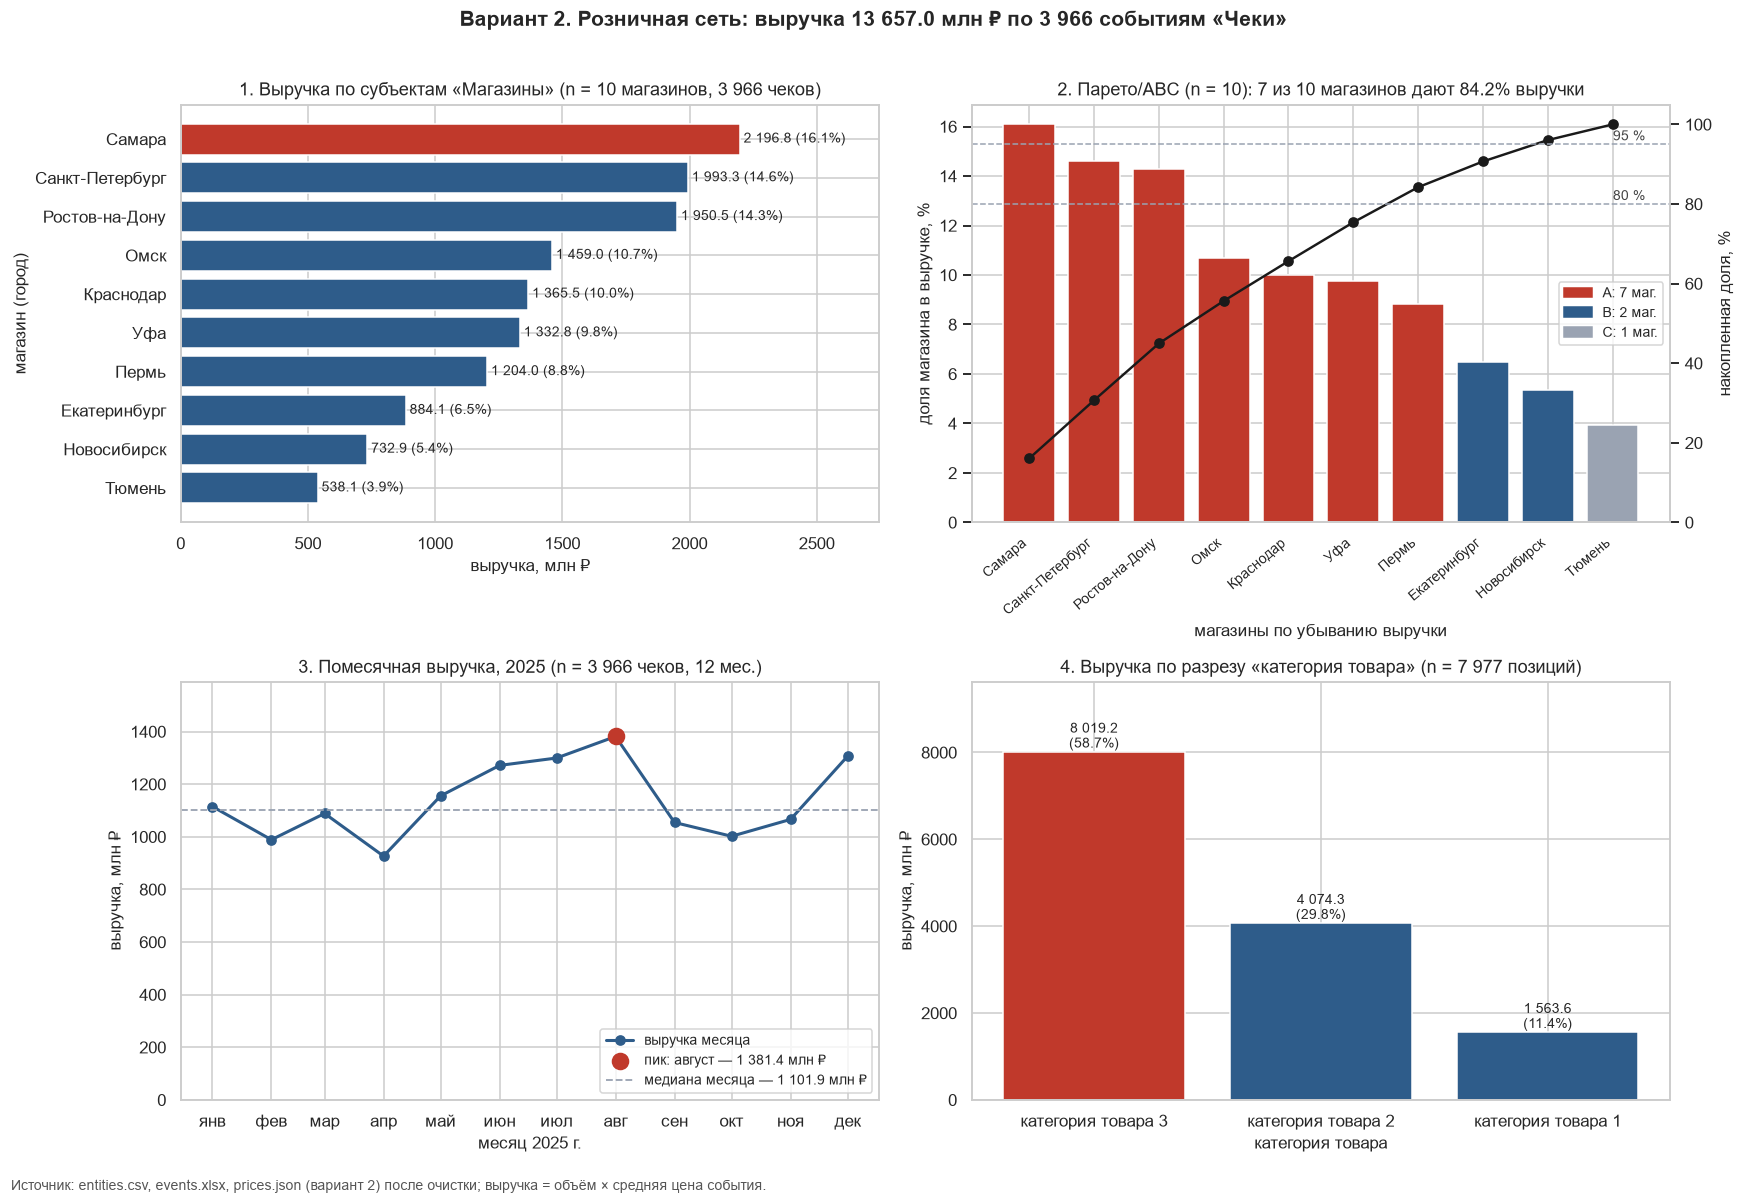

ABC-АНАЛИЗ МАГАЗИНОВ


,ранг,entity_id,entity_name,events_cnt,revenue,"средний чек, ₽",доля,накопленная доля,группа ABC
0,1,E001,Магазины «Самара»,650,"2,196,809,756.75","3,379,707.32",0.16,0.16,A
1,2,E002,Магазины «Санкт-Петербург»,579,"1,993,303,122.11","3,442,665.15",0.15,0.31,A
2,3,E003,Магазины «Ростов-на-Дону»,564,"1,950,497,468.74","3,458,328.85",0.14,0.45,A
3,4,E004,Магазины «Омск»,435,"1,458,964,612.33","3,353,941.64",0.11,0.56,A
4,5,E005,Магазины «Краснодар»,405,"1,365,541,884.68","3,371,708.36",0.10,0.66,A
5,6,E006,Магазины «Уфа»,386,"1,332,798,927.28","3,452,846.96",0.10,0.75,A
6,7,E007,Магазины «Пермь»,337,"1,203,966,779.04","3,572,601.72",0.09,0.84,A
7,8,E008,Магазины «Екатеринбург»,245,"884,073,908.60","3,608,464.93",0.06,0.91,B
8,9,E009,Магазины «Новосибирск»,197,"732,932,755.30","3,720,470.84",0.05,0.96,B
9,10,E010,Магазины «Тюмень»,168,"538,102,976.88","3,202,993.91",0.04,1.00,C


СЕЗОННОСТЬ


,month,revenue,events,volume,"к медиане, %"
0,2025-01,"1,115,098,500.57",352,"66,495.00",101.20
1,2025-02,"988,924,349.58",302,"56,185.00",89.70
2,2025-03,"1,088,787,501.58",345,"66,704.00",98.80
3,2025-04,"926,676,554.49",308,"56,666.00",84.10
4,2025-05,"1,155,658,075.88",359,"68,461.00",104.90
5,2025-06,"1,271,482,874.50",318,"77,776.00",115.40
6,2025-07,"1,299,642,048.14",318,"78,185.00",117.90
7,2025-08,"1,381,420,526.35",321,"77,031.00",125.40
8,2025-09,"1,054,537,242.29",344,"63,855.00",95.70
9,2025-10,"1,002,124,827.35",319,"61,021.00",90.90


СТРУКТУРА ПО РАЗРЕЗУ «категория товара»


,price_class,revenue,price_rows,avg_price,доля
0,категория товара 3,"8,019,157,032.94",2675,"29,539.12",0.59
1,категория товара 2,"4,074,254,699.34",2639,"15,049.31",0.30
2,категория товара 1,"1,563,580,459.45",2663,"5,741.12",0.11


Витрина выгружена: pw2_work\mart_variant_2.xlsx

================================ ВЫВОДЫ ДЛЯ ЛПР ================================
Вариант 2 · Розничная сеть · ABC-анализ магазинов: какие точки дают 80 % выручки
Данные: 10 магазинов, 3 966 чеков с ценой, 7 977 позиций;
в карантине 135 строк (1.1% исходных событий и цен); чеков без пригодной цены: 1.
Итоговая выручка (корректный расчёт): 13 656 992 192 ₽ = 13 657.0 млн ₽.

1. Концентрация (ABC). 80 % выручки дают 7 из 10 магазинов (группа A, 84.2%):
   Самара, Санкт-Петербург, Ростов-на-Дону, Омск, Краснодар, Уфа, Пермь.
   Без последнего из них (Пермь) первые 6 дают только
   75.4% — порог 80 % пересекается на 7-м магазине.
   Лидер — Магазины «Самара»: 16.1% выручки, 2 196.8 млн ₽;
   группа C (1 маг.: Тюмень) — 3.9%.
   Концентрация умеренная: доля лидера 16.1%, «одной точки отказа» нет, но разрыв лидера
   и замыкающего (Тюмень) — 4.1 раза. Средний чек по
   магазинам отличается не более чем на 16.2% (max/min), а число чеков — в
   3

In [ ]:
#@title Шаг 6. Аналитика и визуализация (задание) { display-mode: "form" }
# ------------------------------------------------------------------ TODO 6.1
# Постройте четыре графика:
#   1) выручка по субъектам с выделением лидера;
#   2) диаграмма Парето с накопленной долей и группами ABC (порог 80 % и 95 %);
#   3) помесячная динамика выручки с отметкой пика и медианы;
#   4) структура выручки по разрезу цен (CFG["cls"]).
# Требования: заголовок с объёмом выборки, подписи осей с единицами, единая палитра,
# один акцентный цвет на выделяемый объект.
ACCENT, BASE, LIGHT, GREY = "#c0392b", "#2e5c8a", "#8fb3d9", "#9aa3b2"
RU_MONTHS = ["янв", "фев", "мар", "апр", "май", "июн", "июл", "авг", "сен", "окт", "ноя", "дек"]
RU_MONTHS_FULL = ["январь", "февраль", "март", "апрель", "май", "июнь", "июль", "август",
                  "сентябрь", "октябрь", "ноябрь", "декабрь"]
total_revenue = float(revenue_pd["revenue"].sum())
n_events_rev = len(consolidated)
short = lambda name: name.split("«")[-1].rstrip("»")          # «Магазины «Казань»» → «Казань»

# ---------------- срез 1 и 2: рейтинг и ABC ------------------------------------------
# Группа A — минимальный набор магазинов, который вместе даёт 80 % выручки:
# магазин входит в A, если накопленная доля ДО него меньше 80 % (аналогично 95 % для B).
pareto = revenue_pd.sort_values("revenue", ascending=False, ignore_index=True)
pareto["доля"] = pareto["revenue"] / total_revenue
pareto["накопленная доля"] = pareto["доля"].cumsum()
prev_cum = pareto["накопленная доля"].shift(fill_value=0)
pareto["группа ABC"] = np.select([prev_cum < 0.80, prev_cum < 0.95], ["A", "B"], "C")
pareto["средний чек, ₽"] = pareto["revenue"] / pareto["events_cnt"]
pareto["ранг"] = np.arange(1, len(pareto) + 1)

# ---------------- срез 3: сезонность -------------------------------------------------
monthly = (consolidated.assign(month=consolidated["event_date"].dt.to_period("M").dt.to_timestamp())
           .groupby("month", as_index=False)
           .agg(revenue=("event_revenue", "sum"), events=("event_id", "count"),
                volume=("volume_units", "sum")))
peak = monthly.loc[monthly["revenue"].idxmax()]
low = monthly.loc[monthly["revenue"].idxmin()]

# ---------------- срез 4: структура по классам цен -----------------------------------
# Выручка события = объём × средняя цена = Σ (объём × цена_i / n). Делим её между ценовыми
# строками поровну — так сумма по классам совпадает с итогом и повторного fan-out нет.
by_class_rows = (prices_valid.merge(consolidated[["event_id", "volume_units", "price_rows"]], on="event_id")
                 .assign(revenue=lambda d: d["volume_units"] * d["unit_price"] / d["price_rows"]))
by_class = (by_class_rows.groupby("price_class", as_index=False)
            .agg(revenue=("revenue", "sum"), price_rows=("price_id", "count"),
                 avg_price=("unit_price", "mean"))
            .sort_values("revenue", ascending=False, ignore_index=True))
by_class["доля"] = by_class["revenue"] / total_revenue

# ---------------- контроль сходимости срезов ------------------------------------------
convergence = pd.DataFrame([
    {"срез": "итог (SQL, корректный расчёт)", "сумма, ₽": float(revenue_sql["revenue"].sum())},
    {"срез": f"по субъектам «{CFG['parent']}»", "сумма, ₽": float(pareto["revenue"].sum())},
    {"срез": "по группам ABC", "сумма, ₽": float(pareto.groupby("группа ABC")["revenue"].sum().sum())},
    {"срез": "по месяцам", "сумма, ₽": float(monthly["revenue"].sum())},
    {"срез": f"по разрезу «{CFG['cls']}»", "сумма, ₽": float(by_class["revenue"].sum())},
    {"срез": "витрина mart_event_revenue (SQLite)",
     "сумма, ₽": float(conn.execute("SELECT SUM(event_revenue) FROM mart_event_revenue").fetchone()[0])},
])
convergence["отклонение от итога pandas, ₽"] = (convergence["сумма, ₽"] - total_revenue).round(4)
print("КОНТРОЛЬ СХОДИМОСТИ: сумма по любому разрезу = итоговая выручка")
display(convergence)
assert convergence["отклонение от итога pandas, ₽"].abs().max() < 1.0, "Срез не сходится с итогом"

# ---------------- графики -------------------------------------------------------------
def mln(v):
    return f"{v / 1e6:,.1f}".replace(",", " ")

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle(f"Вариант {VARIANT}. {CFG['domain']}: выручка {nf(total_revenue / 1e6, 1)} млн ₽ "
             f"по {nf(n_events_rev)} событиям «{CFG['event']}»", fontsize=14, fontweight="bold")

# 1. Рейтинг магазинов, лидер выделен
ax = axes[0, 0]
top = pareto.sort_values("revenue")
ax.barh(top["entity_name"].map(short), top["revenue"] / 1e6,
        color=[ACCENT if r == 1 else BASE for r in top["ранг"]])
for y, (v, s) in enumerate(zip(top["revenue"], top["доля"])):
    ax.text(v / 1e6, y, f" {mln(v)} ({s:.1%})", va="center", fontsize=9)
ax.set_title(f"1. Выручка по субъектам «{CFG['parent']}» (n = {len(top)} магазинов, "
             f"{nf(n_events_rev)} чеков)")
ax.set_xlabel("выручка, млн ₽"); ax.set_ylabel("магазин (город)")
ax.set_xlim(0, top["revenue"].max() / 1e6 * 1.25)

# 2. Парето + ABC
ax = axes[0, 1]
x = np.arange(len(pareto))
abc_color = {"A": ACCENT, "B": BASE, "C": GREY}
ax.bar(x, pareto["доля"] * 100, color=pareto["группа ABC"].map(abc_color))
ax.set_xticks(x, pareto["entity_name"].map(short), rotation=40, ha="right", fontsize=9)
ax.set_ylabel("доля магазина в выручке, %"); ax.set_xlabel("магазины по убыванию выручки")
ax2 = ax.twinx()
ax2.plot(x, pareto["накопленная доля"] * 100, color="#1a1a1a", marker="o", lw=1.6, label="накопленная доля")
for level in (80, 95):
    ax2.axhline(level, color=GREY, ls="--", lw=1)
    ax2.text(len(pareto) - 0.5, level + 1, f"{level} %", ha="right", fontsize=9, color="#444")
ax2.set_ylim(0, 105); ax2.set_ylabel("накопленная доля, %"); ax2.grid(False)
n_a, n_b, n_c = [int((pareto["группа ABC"] == g).sum()) for g in "ABC"]
share_a = float(pareto.loc[pareto["группа ABC"] == "A", "доля"].sum())
handles = [plt.Rectangle((0, 0), 1, 1, color=abc_color[g]) for g in "ABC"]
ax.legend(handles, [f"A: {n_a} маг.", f"B: {n_b} маг.", f"C: {n_c} маг."], loc="center right", fontsize=9)
ax.set_title(f"2. Парето/ABC (n = {len(pareto)}): {n_a} из {len(pareto)} магазинов дают {share_a:.1%} выручки")

# 3. Сезонность
ax = axes[1, 0]
ax.plot(monthly["month"], monthly["revenue"] / 1e6, marker="o", color=BASE, lw=2, label="выручка месяца")
ax.scatter([peak["month"]], [peak["revenue"] / 1e6], color=ACCENT, s=110, zorder=3,
           label=f"пик: {RU_MONTHS_FULL[peak['month'].month - 1]} — {mln(peak['revenue'])} млн ₽")
ax.axhline(monthly["revenue"].median() / 1e6, color=GREY, ls="--", lw=1.2,
           label=f"медиана месяца — {mln(monthly['revenue'].median())} млн ₽")
ax.set_xticks(monthly["month"], [RU_MONTHS[m.month - 1] for m in monthly["month"]])
ax.set_title(f"3. Помесячная выручка, 2025 (n = {nf(n_events_rev)} чеков, {len(monthly)} мес.)")
ax.set_xlabel("месяц 2025 г."); ax.set_ylabel("выручка, млн ₽"); ax.legend(fontsize=9, loc="lower right")
ax.set_ylim(0, monthly["revenue"].max() / 1e6 * 1.15)

# 4. Структура по категориям товара
ax = axes[1, 1]
ax.bar(by_class["price_class"], by_class["revenue"] / 1e6,
       color=[ACCENT if i == 0 else BASE for i in range(len(by_class))])
for i, (v, s) in enumerate(zip(by_class["revenue"], by_class["доля"])):
    ax.text(i, v / 1e6, f"{mln(v)}\n({s:.1%})", ha="center", va="bottom", fontsize=9)
ax.set_title(f"4. Выручка по разрезу «{CFG['cls']}» (n = {nf(by_class['price_rows'].sum())} позиций)")
ax.set_xlabel(CFG["cls"]); ax.set_ylabel("выручка, млн ₽")
ax.set_ylim(0, by_class["revenue"].max() / 1e6 * 1.2)

fig.text(0.01, 0.005, f"Источник: entities.csv, events.xlsx, prices.json (вариант {VARIANT}) после очистки; "
         f"выручка = объём × средняя цена события.", fontsize=9, color="#555")
plt.tight_layout(rect=(0, 0.02, 1, 0.97))
fig.savefig(WORK / f"charts_variant_{VARIANT}.png", dpi=130)
plt.show()
PLOTS_DONE = True

print("ABC-АНАЛИЗ МАГАЗИНОВ")
display(pareto[["ранг", "entity_id", "entity_name", "events_cnt", "revenue", "средний чек, ₽",
                "доля", "накопленная доля", "группа ABC"]])
print("СЕЗОННОСТЬ")
display(monthly.assign(month=monthly["month"].dt.strftime("%Y-%m"),
                       **{"к медиане, %": (monthly["revenue"] / monthly["revenue"].median() * 100).round(1)}))
print(f"СТРУКТУРА ПО РАЗРЕЗУ «{CFG['cls']}»")
display(by_class)

# Выгрузка витрины для сдачи
mart_path = WORK / f"mart_variant_{VARIANT}.xlsx"
with pd.ExcelWriter(mart_path) as writer:
    pareto.to_excel(writer, sheet_name="ABC_магазины", index=False)
    monthly.assign(month=monthly["month"].dt.strftime("%Y-%m")).to_excel(writer, sheet_name="сезонность", index=False)
    by_class.to_excel(writer, sheet_name="категории", index=False)
    pd.read_sql("SELECT * FROM mart_event_revenue", conn).to_excel(writer, sheet_name="витрина_события", index=False)
    clean_log_df.to_excel(writer, sheet_name="журнал_очистки", index=False)
    quality.to_excel(writer, sheet_name="журнал_качества", index=False)
print(f"Витрина выгружена: {mart_path}")

# ------------------------------------------------------------------ TODO 6.2
# Сформируйте выводы для ЛПР: концентрация выручки, сезонность, влияние качества данных
# (коэффициент завышения из шага 5) и три рекомендации с ожидаемым эффектом.
leader = pareto.iloc[0]
outsider = pareto.iloc[-1]
group_a = pareto[pareto["группа ABC"] == "A"]
group_c = pareto[pareto["группа ABC"] == "C"]
season_gap = float(peak["revenue"] / low["revenue"])
summer_dec = monthly[monthly["month"].dt.month.isin([6, 7, 8, 12])]
other = monthly[~monthly["month"].dt.month.isin([6, 7, 8, 12])]
season_lift = float(summer_dec["revenue"].mean() / other["revenue"].mean() - 1)
q_rows = len(quarantine_events) + len(quarantine_price)
q_share = q_rows / (len(raw_events) + len(raw_prices))
q_volume = float(quarantine_events["volume_units"].sum())
top_class = by_class.iloc[0]
check_gap = float(pareto["средний чек, ₽"].max() / pareto["средний чек, ₽"].min() - 1)
one_pp = total_revenue * 0.01

conclusions = f"""
================================ ВЫВОДЫ ДЛЯ ЛПР ================================
Вариант {VARIANT} · {CFG['domain']} · {CFG['analytics']}
Данные: {len(entities)} магазинов, {nf(n_events_rev)} чеков с ценой, {nf(len(prices_valid))} позиций;
в карантине {q_rows} строк ({q_share:.1%} исходных событий и цен); чеков без пригодной цены: {len(events_no_price)}.
Итоговая выручка (корректный расчёт): {nf(total_revenue)} ₽ = {nf(total_revenue / 1e6, 1)} млн ₽.

1. Концентрация (ABC). 80 % выручки дают {n_a} из {len(pareto)} магазинов (группа A, {share_a:.1%}):
   {", ".join(group_a["entity_name"].map(short))}.
   Без последнего из них ({short(group_a['entity_name'].iloc[-1])}) первые {n_a - 1} дают только
   {pareto['накопленная доля'].iloc[n_a - 2]:.1%} — порог 80 % пересекается на {n_a}-м магазине.
   Лидер — {leader['entity_name']}: {leader['доля']:.1%} выручки, {nf(leader['revenue'] / 1e6, 1)} млн ₽;
   группа C ({n_c} маг.: {", ".join(group_c["entity_name"].map(short))}) — {group_c['доля'].sum():.1%}.
   Концентрация умеренная: доля лидера {leader['доля']:.1%}, «одной точки отказа» нет, но разрыв лидера
   и замыкающего ({short(outsider['entity_name'])}) — {leader['revenue'] / outsider['revenue']:.1f} раза. Средний чек по
   магазинам отличается не более чем на {check_gap:.1%} (max/min), а число чеков — в
   {pareto['events_cnt'].max() / pareto['events_cnt'].min():.1f} раза: разницу в выручке создаёт трафик, а не чек.
2. Сезонность. Пик — {RU_MONTHS_FULL[int(peak['month'].month) - 1]} ({nf(peak['revenue'] / 1e6, 1)} млн ₽), минимум —
   {RU_MONTHS_FULL[int(low['month'].month) - 1]} ({nf(low['revenue'] / 1e6, 1)} млн ₽), разрыв {season_gap:.2f} раза.
   Июнь–август и декабрь в среднем на {season_lift:.1%} выше остальных месяцев.
3. Структура. Крупнейший вклад — «{top_class['price_class']}» ({top_class['доля']:.1%} выручки) при доле
   позиций {top_class['price_rows'] / by_class['price_rows'].sum():.1%}: категория даёт больше выручки за счёт цены
   (средняя {nf(top_class['avg_price'])} ₽ против {nf(by_class['avg_price'].min())} ₽ у самой дешёвой), а не за счёт числа позиций.
4. Качество данных. Наивный JOIN завысил бы выручку в {overstate:.2f} раза
   ({nf(compare['revenue_naive'].sum() / 1e6, 1)} млн ₽ вместо {nf(total_revenue / 1e6, 1)} млн ₽).
   SQL и pandas совпали с точностью {delta:.4f} ₽.

РЕКОМЕНДАЦИИ (действие → основание → ожидаемый эффект → как проверить)
R1. Программа удержания трафика в магазинах группы A ({n_a} маг.).
    Основание: группа A = {share_a:.1%} выручки; каждый 1 % выручки сети = {nf(one_pp / 1e6, 1)} млн ₽.
    Эффект: рост числа чеков в группе A на 3 % даёт ≈ {nf(share_a * total_revenue * 0.03 / 1e6, 1)} млн ₽ в год
    (оценка при неизменном среднем чеке).
    Проверка: A/B-сравнение числа чеков и выручки магазинов A с прошлым годом и с контрольными
    магазинами помесячно; пересчёт ABC каждый квартал по этой же витрине.
R2. Планировать запасы и персонал по помесячному профилю, а не по среднему году.
    Основание: пик/минимум = {season_gap:.2f}, сезон (июнь–август, декабрь) +{season_lift:.1%} к остальным месяцам.
    Эффект: меньше дефицита в пик и простоя в низкий сезон; целевой ориентир — доля упущенных продаж
    (out-of-stock) в пиковые месяцы не выше, чем в обычные.
    Проверка: план-факт выручки и остатков по месяцам; сравнить отклонение прогноза по профилю
    и по среднему за следующий год.
R3. Ввести контроль качества на входе и регламент расчёта выручки «свёртка цен → JOIN».
    Основание: наивный JOIN завышает выручку в {overstate:.2f} раза; в карантине {q_rows} строк, из них
    {len(quarantine_fk)} чеков с несуществующим магазином E999 (объём {nf(quarantine_fk['volume_units'].sum())} {CFG['unit']}),
    {int(len(removed_duplicates['События']) + len(removed_duplicates['Цены']))} дублей чеков и позиций удалено.
    Эффект: исключается двойной счёт и завышение отчётной выручки; {nf(q_volume)} {CFG['unit']} из чеков
    в карантине после исправления источника вернутся в отчёт.
    Проверка: автотест сверки SQL = pandas и «сумма срезов = итог» при каждой загрузке; доля карантина
    в журнале ≤ 1 % и снижается от выгрузки к выгрузке.

ОГРАНИЧЕНИЯ ДАННЫХ
• Данные синтетические, один год (2025): тренд и межгодовую сезонность оценить нельзя.
• Цена события — простое среднее по позициям: без количества по категориям выручка приблизительна
  (взвешенная цена может заметно её изменить).
• Не входят в выручку: чеки без цены ({len(events_no_price)}) и чеки в карантине ({len(quarantine_events)}) — итог занижен на их долю.
• У {len(quarantine_volume)} чеков нет объёма: их выручку нельзя оценить, пропуск не заменялся нулём.
• Выбросы по 3×IQR не найдены, но это не доказывает точность цен — нужна сверка с кассовыми данными.
================================================================================="""
print(conclusions)
_ = (WORK / f"conclusions_variant_{VARIANT}.txt").write_text(conclusions, encoding="utf-8")

**Интерпретация.** На диаграмме Парето смотрите, сколько субъектов попало в группу A: это и есть ответ на вопрос «где сосредоточено управленческое внимание». На сезонности сравните пик и провал: разрыв в полтора-два раза означает, что планирование по среднегодовому значению даст дефицит мощностей летом и простой зимой. В структуре по классам главное — строка контроля сходимости: ноль подтверждает, что при разрезании выручки вы не размножили её повторно.

Выводы для ЛПР — не пересказ графиков, а решения: что делать, на каком основании и как проверить результат.

>**Результат шага 6 (вариант 2) — ответ на аналитическую задачу «какие точки дают 80 % выручки».**
>
>* **ABC.** 80 % выручки дают **7 из 10 магазинов** (группа A, 84,2 %): Самара, Санкт-Петербург, Ростов-на-Дону, Омск, Краснодар, Уфа, Пермь. Первые шесть магазинов набирают только 75,4 %, поэтому порог 80 % пересекается на Перми. В группу B входят Екатеринбург и Новосибирск (накопленно 96,1 %), в группу C — Тюмень (3,9 %).
>* **Лидер** — «Самара»: 16,1 % выручки, 2 196,8 млн ₽. Это в 4,1 раза больше, чем у Тюмени. Средний чек по магазинам почти одинаков (3,2–3,7 млн ₽), а число чеков различается в 3,9 раза. Значит, разницу в выручке создаёт трафик.
>* **Сезонность.** Пик — август (1 381,4 млн ₽), минимум — апрель (926,7 млн ₽), разрыв 1,49 раза. Июнь–август и декабрь в среднем на 25 % выше остальных месяцев.
>* **Структура.** «Категория товара 3» даёт 58,7 % выручки при трети позиций. Причина в цене: средняя 29,5 тыс. ₽ против 5,7 тыс. ₽ у категории 1.
>* **Сходимость.** Сумма по магазинам, группам ABC, месяцам, категориям и витрине совпадает с итогом с точностью до 0,02 ₽. Повторного fan-out в срезах нет.
>
>Витрина выгружена в `mart_variant_2.xlsx`: ABC, сезонность, категории, событийная витрина, журналы очистки и качества. Графики — в `charts_variant_2.png`. Три рекомендации в формате «действие → основание → эффект → проверка» и ограничения данных выведены в ячейке выше и сохранены в `conclusions_variant_2.txt`.

## Шаг 7. BigQuery: пошаговое подключение из Colab

Показать, как та же витрина переносится в облачное хранилище, когда данных становится слишком много для одной машины.

### Шаг 1. Аккаунт и проект

1. Откройте <https://console.cloud.google.com> и войдите в аккаунт Google.
2. Вверху нажмите селектор проектов → **New Project**, задайте имя (например, `pw2-consolidation`) и создайте проект.
3. Скопируйте **Project ID** — это не название, а идентификатор вида `pw2-consolidation-123456`. Он понадобится в коде.

### Шаг 2. Режим работы: sandbox или биллинг

* **BigQuery sandbox** — без привязки карты. Бесплатно: 10 ГБ хранения и 1 ТБ обработанных запросами данных в месяц. Ограничения: нет DML-операций в части сценариев, таблицы автоматически удаляются через 60 дней. Для этой работы sandbox достаточно.
* **С биллингом** — снимаются ограничения sandbox, бесплатные лимиты те же. Карта привязывается в разделе **Billing**.

### Шаг 3. Включение API

В консоли: **APIs & Services → Library → BigQuery API → Enable**. Без этого библиотека вернёт ошибку доступа.

### Шаг 4. Аутентификация в Colab

```python
from google.colab import auth
auth.authenticate_user()     # откроется окно входа в Google-аккаунт
```

Вне Colab используется либо `gcloud auth application-default login`, либо ключ сервисного аккаунта: **IAM & Admin → Service Accounts → Create** → роль **BigQuery Data Editor** и **BigQuery Job User** → **Keys → Add key (JSON)**. Путь к файлу ключа кладётся в переменную окружения `GOOGLE_APPLICATION_CREDENTIALS`.

> Файл ключа — это пароль от проекта. Его нельзя коммитить в репозиторий и нельзя оставлять в выводе ячейки.

### Шаг 5. Датасет

Датасет — контейнер таблиц с привязкой к региону (`US`, `EU`, `europe-west3`). Регион выбирается один раз: соединять таблицы из разных регионов нельзя. Создаётся кодом в ячейке ниже (`create_dataset(..., exists_ok=True)`) или в консоли кнопкой **Create dataset**.

### Шаг 6. Загрузка и запрос

Код ячейки делает следующее:

1. загружает три очищенные таблицы через `load_table_from_dataframe` с режимом `WRITE_TRUNCATE` (перезапись — повторный запуск не плодит дубликаты);
2. выполняет **сухой прогон** (`dry_run=True`), который показывает, сколько байт прочитает запрос, ничего не тратя, — привычка, экономящая бюджет;
3. выполняет тот же корректный расчёт выручки, что и в SQLite;
4. сверяет результат с SQLite: цифры обязаны совпасть.

### Шаг 7. Стоимость и правила экономии

Оплата в BigQuery берётся за **объём прочитанных данных**, а не за время. Отсюда практические правила:

* не писать `SELECT *` — читаются только перечисленные колонки (колоночное хранение);
* использовать партиционирование по дате и кластеризацию по ключу фильтрации;
* перед тяжёлым запросом делать `dry_run`;
* учебные наборы этой работы весят единицы мегабайт, то есть укладываются в бесплатный лимит с огромным запасом.

### Отличия синтаксиса от SQLite

| | SQLite | BigQuery (GoogleSQL) |
|---|---|---|
| Идентификаторы | `"table"` или без кавычек | `` `project.dataset.table` `` |
| Типы дат | текст `YYYY-MM-DD` | `DATE`, `TIMESTAMP` |
| Приведение типа | `CAST(x AS REAL)` | `CAST(x AS FLOAT64)`, `SAFE_CAST` |
| Ключи | `PRIMARY KEY`, `FOREIGN KEY` | ограничения не проверяются: целостность обеспечивает конвейер |
| Пагинация | `LIMIT n OFFSET m` | `LIMIT n OFFSET m`, но для больших выборок — экспорт |

Последняя строка таблицы — важный профессиональный вывод: в аналитических хранилищах контроль качества не делегируется базе. Всё, что вы сделали на шагах 3–4, в промышленном контуре становится обязательным этапом конвейера.

In [ ]:
#@title Шаг 7. Выгрузка витрины в BigQuery { display-mode: "form" }
# Ячейка ничего не делает, пока ENABLE_BIGQUERY = False в шаге 1.
# Перед включением выполните шаги из markdown-инструкции выше: проект, sandbox, датасет.
BQ_PROJECT_ID = "my-gcp-project"   #@param {type:"string"}
BQ_DATASET = "pw2_consolidation"   #@param {type:"string"}
BQ_LOCATION = "US"                 #@param ["US", "EU", "europe-west3", "asia-northeast1"]

if not ENABLE_BIGQUERY:
    print("BigQuery отключён (ENABLE_BIGQUERY = False). Раздел необязателен: "
          "основная часть работы выполняется на SQLite.")
else:
    ensure("google-cloud-bigquery", "google.cloud.bigquery")
    ensure("pandas-gbq", "pandas_gbq")
    from google.cloud import bigquery

    # 1. Аутентификация: в Colab открывает окно входа в Google-аккаунт
    try:
        from google.colab import auth
        auth.authenticate_user()
        print("Аутентификация в Colab выполнена")
    except ImportError:
        print("Не Colab: используйте `gcloud auth application-default login` "
              "или переменную GOOGLE_APPLICATION_CREDENTIALS с путём к ключу сервисного аккаунта")

    client = bigquery.Client(project=BQ_PROJECT_ID, location=BQ_LOCATION)

    # 2. Датасет создаётся, если его ещё нет
    dataset_ref = bigquery.Dataset(f"{BQ_PROJECT_ID}.{BQ_DATASET}")
    dataset_ref.location = BQ_LOCATION
    client.create_dataset(dataset_ref, exists_ok=True)
    print(f"Датасет готов: {BQ_PROJECT_ID}.{BQ_DATASET} ({BQ_LOCATION})")

    # 3. Загрузка трёх очищенных таблиц
    for name, frame in [("entities", entities),
                        ("events", events_out),
                        ("prices", prices_valid[["price_id", "event_id", "unit_price", "price_class"]])]:
        job = client.load_table_from_dataframe(
            frame, f"{BQ_PROJECT_ID}.{BQ_DATASET}.{name}",
            job_config=bigquery.LoadJobConfig(write_disposition="WRITE_TRUNCATE"))
        job.result()
        print(f"  загружено {name}: {nf(len(frame))} строк")

    # 4. Тот же корректный расчёт выручки, но на стороне BigQuery
    bq_sql = f"""
    WITH price_per_event AS (
        SELECT event_id, AVG(unit_price) AS avg_price
        FROM `{BQ_PROJECT_ID}.{BQ_DATASET}.prices`
        GROUP BY event_id
    )
    SELECT e.entity_name,
           COUNT(ev.event_id)                            AS events_cnt,
           ROUND(SUM(ev.volume_units * pe.avg_price), 2) AS revenue
    FROM `{BQ_PROJECT_ID}.{BQ_DATASET}.entities` e
    JOIN `{BQ_PROJECT_ID}.{BQ_DATASET}.events` ev ON ev.entity_id = e.entity_id
    JOIN price_per_event pe ON pe.event_id = ev.event_id
    GROUP BY e.entity_name
    ORDER BY revenue DESC
    """

    # 5. Сухой прогон: сколько байт прочитает запрос (в sandbox бесплатно 1 ТБ в месяц)
    dry = client.query(bq_sql, job_config=bigquery.QueryJobConfig(dry_run=True, use_query_cache=False))
    print(f"\nОценка объёма чтения: {dry.total_bytes_processed / 1024**2:.2f} МБ "
          f"(бесплатный лимит — 1 ТБ в месяц)")

    revenue_bq = client.query(bq_sql).to_dataframe()
    display(revenue_bq.head(10))

    # 6. Сверка с SQLite: цифры обязаны совпасть
    check = (revenue_bq.set_index("entity_name")["revenue"]
             - revenue_sql.set_index("entity_name")["revenue"]).abs().max()
    print(f"Максимальное расхождение BigQuery и SQLite: {check:.4f}")

BigQuery отключён (ENABLE_BIGQUERY = False). Раздел необязателен: основная часть работы выполняется на SQLite.


## Таблица вариантов (30 вариантов)

Номер варианта выдаёт преподаватель; он подставляется в поле `VARIANT` шага 1 и определяет предметную область, объём генерации и набор дефектов (столбец «Дефекты»: ★ — базовый набор, ★★ — добавляются битые внешние ключи и отрицательные цены, ★★★ — ещё и дубликаты записей).

Архитектура данных во всех вариантах одинакова: справочник субъектов (CSV) → события с объёмом (XLSX) → цены по событиям, несколько строк на событие (JSON). Считается выручка по субъектам.

| № | Предметная область | CSV: справочник | XLSX: события | JSON: цены | Единица объёма | Разрез цен | Аналитическая задача | Дефекты |
|---:|---|---|---|---|---|---|---|:--:|
| 1 | Авиаперевозки | Авиакомпании | Рейсы | Билеты | пассажиров | класс билета | Сезонность перевозок: в каком месяце выручка максимальна и какие компании её формируют | ★★ |
| 2 | Розничная сеть | Магазины | Чеки | Позиции чека | единиц товара | категория товара | ABC-анализ магазинов: какие точки дают 80 % выручки | ★★★ |
| 3 | Логистика | Перевозчики | Отгрузки | Тарифы | паллет | тип тарифа | Загрузка перевозчиков: связь объёма и средней ставки | ★ |
| 4 | Телеком | Операторы | Сессии связи | Тарификация | минут | тарифный план | Доля тарифных планов в выручке и средний чек сессии | ★★ |
| 5 | Банковский ритейл | Отделения | Операции | Комиссии | транзакций | тип комиссии | Эффективность отделений: выручка на одну операцию | ★★★ |
| 6 | Гостиничный бизнес | Отели | Бронирования | Тарифы номеров | ночей | категория номера | Сезонность загрузки и вклад категорий номеров | ★ |
| 7 | Образовательные услуги | Центры | Группы | Стоимость обучения | слушателей | формат обучения | Выручка на слушателя и сравнение форматов | ★★ |
| 8 | Медицинские клиники | Клиники | Приёмы | Прейскурант | пациентов | вид услуги | Структура выручки по видам услуг и загрузка клиник | ★★★ |
| 9 | Энергосбыт | Сбытовые компании | Поставки | Тарифы | МВт·ч | категория потребителя | Концентрация выручки по категориям потребителей | ★ |
| 10 | Маркетплейс | Продавцы | Заказы | Цены товаров | единиц | категория товара | Топ продавцов и доля категорий в обороте | ★★ |
| 11 | Общественный транспорт | Перевозчики | Маршруты-рейсы | Тарифы проезда | пассажиров | тип билета | Выручка по типам билетов и пиковые месяцы | ★★★ |
| 12 | Страхование | Агентства | Договоры | Тарифные ставки | объектов | вид страхования | Средняя премия по видам страхования и вклад агентств | ★ |
| 13 | Грузовые ж/д перевозки | Операторы вагонов | Отправки | Ставки | тонн | род груза | Доходность по родам груза и сезонность отправок | ★★ |
| 14 | Общепит | Рестораны | Заказы | Цены блюд | порций | категория меню | Средний чек и вклад категорий меню | ★★★ |
| 15 | Фитнес-сети | Клубы | Визиты и покупки | Прайс услуг | услуг | тип абонемента | Выручка на клуб и структура абонементов | ★ |
| 16 | Аренда спецтехники | Парки техники | Смены аренды | Ставки аренды | машино-часов | тип техники | Утилизация парка и доходность типов техники | ★★ |
| 17 | Курьерская доставка | Службы доставки | Доставки | Тарифы | посылок | скорость доставки | Доля экспресс-доставки в выручке | ★★★ |
| 18 | Оптовая торговля | Дистрибьюторы | Поставки | Прайс-листы | коробов | товарная группа | Парето по товарным группам и вклад дистрибьюторов | ★ |
| 19 | Автосервис | Сервисные центры | Заказ-наряды | Прейскурант работ | нормо-часов | вид работ | Выручка по видам работ и загрузка центров | ★★ |
| 20 | Цифровые подписки | Сервисы | Подписки | Тарифные планы | подписчиков | план подписки | Структура подписной базы и выручка на подписчика | ★★★ |
| 21 | Сельхозпроизводство | Хозяйства | Партии отгрузки | Закупочные цены | тонн | культура | Доходность культур и сезонность отгрузок | ★ |
| 22 | Строительный ритейл | Гипермаркеты | Продажи | Цены материалов | единиц | группа материалов | Сезонность продаж и вклад групп материалов | ★★ |
| 23 | Морские перевозки | Судоходные линии | Рейсы судов | Фрахтовые ставки | TEU | тип контейнера | Доходность линий и структура по типам контейнеров | ★★★ |
| 24 | Аптечные сети | Аптеки | Продажи | Цены препаратов | упаковок | группа препаратов | Вклад товарных групп и сравнение точек | ★ |
| 25 | Кинотеатры | Кинотеатры | Сеансы | Цены билетов | зрителей | тип сеанса | Заполняемость залов и выручка по типам сеансов | ★★ |
| 26 | Промышленное производство | Заводы | Партии продукции | Отпускные цены | тонн | марка продукции | Вклад марок продукции и сезонность отгрузок | ★★★ |
| 27 | Рекламные площадки | Площадки | Кампании | Ставки размещения | показов (тыс.) | формат размещения | Доходность форматов и концентрация выручки | ★ |
| 28 | ЖКХ | Управляющие компании | Начисления | Тарифы услуг | объектов | вид услуги | Структура начислений и сравнение управляющих компаний | ★★ |
| 29 | Каршеринг | Операторы | Поездки | Тарифы поездок | минут | класс автомобиля | Выручка на поездку и вклад классов автомобилей | ★★★ |
| 30 | Авиаперевозки (эталон преподавателя) | Авиакомпании | Рейсы | Билеты | пассажиров | класс билета | Полный разбор: качество данных, fan-out при JOIN, сезонность, концентрация выручки | ★ |

Минимум для зачёта: найдено не менее пяти проблем качества, заполнен журнал очистки, показана разница наивного и корректного расчёта, результаты SQL и pandas сошлись.

## Критерии оценивания (10 баллов)

| Блок | Что проверяется | Максимум |
|---|---|---:|
| 1. Источники и загрузка | Три формата прочитаны корректно, без потери ведущих нулей и «умного» приведения типов | 1,0 |
| 2. Аудит качества | Профиль источников; журнал проблем по шести измерениям с числом затронутых строк; расчёт кардинальности связей | 2,0 |
| 3. Очистка | Журнал изменений; карантин вместо тихого удаления; пропуски не заменены нулями; разбор обоих форматов дат и чисел с валютой | 2,0 |
| 4. Модель данных и SQL | Схема с PK, FK, `CHECK` и индексами; `PRAGMA foreign_keys`; корректный запрос с CTE; сверка SQL и pandas | 2,5 |
| 5. Аналитика и визуализация | Четыре среза по варианту; контроль сходимости срезов; оформление графиков | 1,5 |
| 6. Выводы | Решения с основанием, ожидаемым эффектом и способом проверки; названы ограничения данных | 1,0 |

### Шкала

| Баллы | Оценка |
|---|---|
| 9–10 | **A** — конвейер воспроизводим, качество данных проработано, выводы управленческие |
| 8–9 | **B** — данные консолидированы верно, есть недочёты в аудите или оформлении |
| 7–8 | **C** — расчёт верен, но качество данных проработано формально |
| 6–7 | **D** — есть результат, но методика расчёта или очистки содержит ошибки |
| < 6 | **F** — выручка посчитана наивным JOIN, дефекты не найдены, работа не воспроизводится |

### Обязательные требования

1. Расчёт выручки выполнен **после** свёртки цен до уровня события; коэффициент завышения наивного варианта показан числом.
2. Результаты SQL и pandas сходятся с точностью округления.
3. Ни одна строка не удалена без записи в журнале очистки.
4. Пропуски остались пропусками.
5. Все графики подписаны: заголовок с объёмом выборки, оси с единицами измерения.
6. Сумма по любому аналитическому разрезу совпадает с итоговой выручкой.

### Штрафы

| Нарушение | Штраф |
|---|---:|
| Выручка посчитана наивным соединением, эффект fan-out не обнаружен | −2,5 |
| `NaN` заменены нулями «чтобы считалось» | −1,0 |
| Строки удалены без журнала и карантина | −1,0 |
| Нет внешних ключей и ограничений в схеме | −1,0 |
| Расхождение SQL и pandas не объяснено | −1,0 |
| Графики без подписей осей и единиц | −0,5 |
| Ноутбук сдан без выводов ячеек | −1,0 |
| Ключ сервисного аккаунта Google в репозитории | −1,5 и обязательный отзыв ключа |

In [ ]:
#@title Самопроверка перед сдачей { display-mode: "form" }
checks = []
def check(name, condition, hint=""):
    checks.append((name, bool(condition), hint))

check("Вариант выбран корректно", 1 <= VARIANT <= 30)
check("Созданы три источника разных форматов",
      all((DATA / f).exists() for f in ("entities.csv", "events.xlsx", "prices.json")))
check("Проведён аудит качества (журнал не пуст)", len(globals().get("issues", [])) >= 5,
      "найдите проблемы по всем шести измерениям качества")
check("Журнал очистки заполнен", len(globals().get("CLEAN_LOG", [])) >= 4)
check("Пропуски не заменены нулями",
      float(events_valid["volume_units"].min()) > 0 and float(prices_valid["unit_price"].min()) > 0)
check("Нарушения целостности вынесены в карантин, а не удалены молча",
      "quarantine_fk" in globals() and "quarantine_price" in globals())
check("База SQLite создана и заполнена", DB_PATH.exists() and DB_PATH.stat().st_size > 20000)
check("Внешние ключи и ограничения объявлены",
      "REFERENCES" in "".join(r[0] for r in conn.execute(
          "SELECT sql FROM sqlite_master WHERE type='table'").fetchall() if r[0]))
check("Показана разница наивного и корректного расчёта", globals().get("overstate", 0) > 1.05,
      "наивный JOIN обязан завышать выручку — покажите это числом")
check("SQL и pandas сошлись", globals().get("delta", 1e9) < 1.0,
      "расхождение больше рубля означает разную методику расчёта")
check("Построены графики", len(plt.get_fignums()) > 0 or globals().get("PLOTS_DONE", False))

ok = sum(1 for _, passed, _ in checks if passed)
print(f"Выполнено: {ok} из {len(checks)}\n")
for name, passed, hint in checks:
    print(f"  {'✅' if passed else '❌'} {name}" + ("" if passed or not hint else f" — {hint}"))

Выполнено: 11 из 11

  ✅ Вариант выбран корректно
  ✅ Созданы три источника разных форматов
  ✅ Проведён аудит качества (журнал не пуст)
  ✅ Журнал очистки заполнен
  ✅ Пропуски не заменены нулями
  ✅ Нарушения целостности вынесены в карантин, а не удалены молча
  ✅ База SQLite создана и заполнена
  ✅ Внешние ключи и ограничения объявлены
  ✅ Показана разница наивного и корректного расчёта
  ✅ SQL и pandas сошлись
  ✅ Построены графики


## Задание со звёздочкой (до +2 баллов)

Учебная витрина собирается один раз. Промышленная — обновляется, хранит историю и проверяет себя сама. Выберите одно направление и доведите до измеримого результата.

<!-- m5_star_intro -->
### Выбранное направление — A. Инкрементальная загрузка (UPSERT)

**Почему A.** В варианте 2 уровень дефектов ★★★: источники присылают повторы записей. Для розничной сети чеки приходят каждый день, и полная перезапись базы на каждой выгрузке дорогая и рискованная. Главный риск догрузки — задвоение чеков и выручки. Поэтому нужно показать, что повторная загрузка того же пакета ничего не меняет.

**Эксперимент.**
1. Работаем с копией базы шага 5 (`consolidation_variant_2_incremental.sqlite`), основная база не меняется.
2. Генерируем пакет «следующего дня» (01.01.2026): 40 новых чеков с позициями, исправления 5 уже загруженных чеков и 5 позиций, а также дефекты как в исходных данных. Это дубли внутри пакета, чек несуществующего магазина `E999`, цена с «₽», пропуск цены, дата `дд.мм.гггг`, объём с пробелом.
3. Пакет проходит те же функции очистки (`to_number`, `to_date`, проверку ключей). Непригодные строки уходят в карантин.
4. Загружаем через `INSERT … ON CONFLICT DO UPDATE … WHERE … IS NOT …`. Строка обновляется только при реальном изменении значений, всё выполняется в одной транзакции, каждый запуск пишется в `load_log`.
5. Запускаем тот же пакет второй раз.
6. Контроль: результат инкремента сравнивается с полной перезагрузкой «база + пакет».

**Критерии идемпотентности:** после второго запуска число строк и выручка те же, 0 вставок и 0 изменений, дублей `event_id` нет, итог совпадает с полной перезагрузкой.

Пакет 2026-01-01: событий 48 (новых 40, исправлений 5, сирота 1, дублей 2), цен 84

ЖУРНАЛ ЗАГРУЗКИ (load_log)


,run_no,table_name,received,дубли в пакете,quarantined,inserted,updated,unchanged
0,1,events,48,2,1,40,5,0
1,1,prices,84,1,2,76,5,0
2,2,events,48,2,1,0,0,45
3,2,prices,84,1,2,0,0,81


В карантин пакета: [{'event_id': 'EV004041', 'entity_id': 'E999'}] [{'price_id': 'PR0008081', 'unit_price': nan}, {'price_id': 'PR0008157', 'unit_price': 5000.0}]

СОСТОЯНИЕ БАЗЫ


,этап,событий,цен,дублей event_id,"выручка, ₽"
0,до загрузки,3967,7977,0,"13,656,992,191.73"
1,после запуска 1,4007,8053,0,"13,822,889,290.84"
2,после запуска 2 (тот же пакет),4007,8053,0,"13,822,889,290.84"


Полная перезагрузка: 4 007 событий, 8 053 цен, выручка 13 822 889 290.84 ₽
Инкремент (UPSERT): 4 007 событий, 8 053 цен, выручка 13 822 889 290.84 ₽
✅ Идемпотентность доказана: второй запуск — 0 вставок и 0 изменений, число строк и выручка те же; результат UPSERT совпадает с полной перезагрузкой (разница 0.0017 ₽). Прирост выручки за день: 165 897 099.11 ₽.


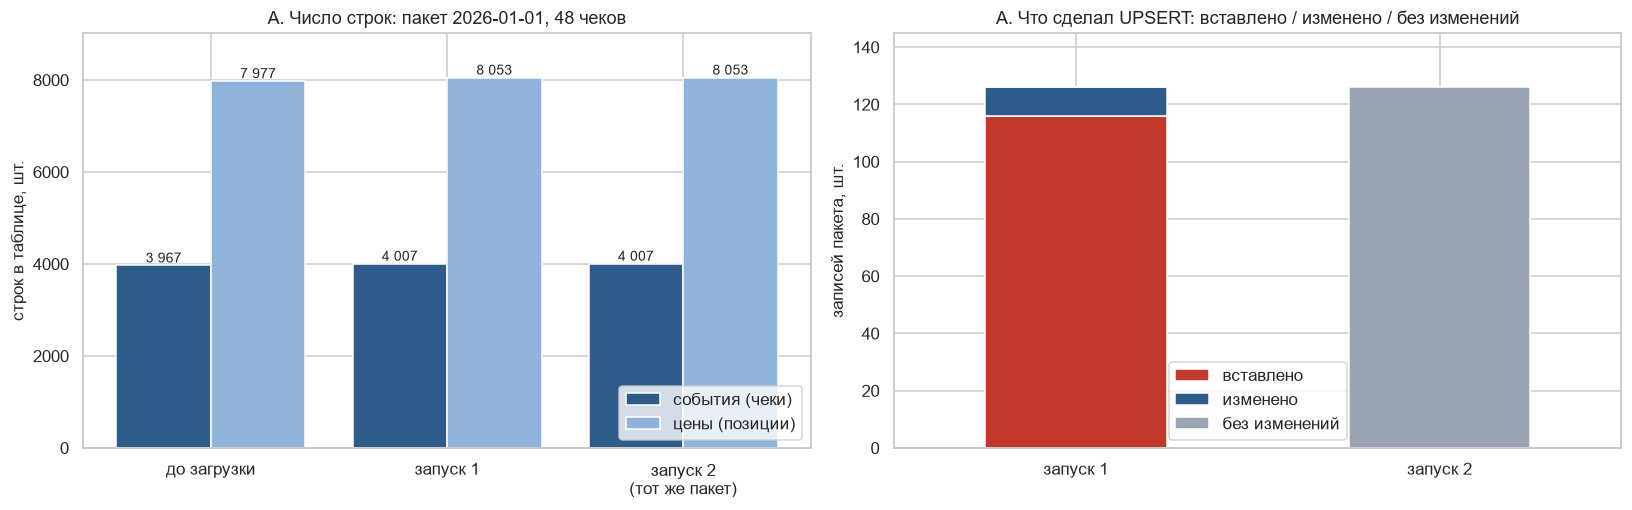

In [ ]:
#@title Задание со звёздочкой (до +2 балла) { display-mode: "form" }
# Выбрано направление A. Инкрементальная загрузка.
#    Сгенерируйте «следующий день» данных и реализуйте догрузку через UPSERT
#    (INSERT ... ON CONFLICT DO UPDATE) вместо полной перезаписи. Покажите, что повторный
#    запуск не создаёт дубликатов (идемпотентность).
#
# План эксперимента:
#   1) копия базы шага 5 (основная база не меняется);
#   2) пакет «следующего дня» в тех же форматах и с теми же дефектами, что и исходные
#      источники: новые чеки, исправления уже загруженных чеков и цен, дубли внутри пакета,
#      чек несуществующего магазина, цена с «₽», пропуск цены;
#   3) пакет проходит те же функции очистки (to_number, to_date, проверка ключей и карантин);
#   4) UPSERT в одной транзакции; DO UPDATE срабатывает только если значение изменилось;
#   5) запуск 1 → запуск 2 тем же пакетом → проверка: строк, выручки и изменённых записей
#      после второго запуска столько же / ноль;
#   6) контроль: результат инкремента совпадает с полной перезагрузкой «база + пакет».
STAR_DB = WORK / f"consolidation_variant_{VARIANT}_incremental.sqlite"
if STAR_DB.exists():
    STAR_DB.unlink()
star = sqlite3.connect(STAR_DB)
conn.backup(star)
star.execute("PRAGMA foreign_keys = ON")
star.executescript("""
CREATE TABLE IF NOT EXISTS load_log (
    batch_id   TEXT NOT NULL,
    run_no     INTEGER NOT NULL,
    loaded_at  TEXT NOT NULL,
    table_name TEXT NOT NULL,
    received   INTEGER NOT NULL,
    inserted   INTEGER NOT NULL,
    updated    INTEGER NOT NULL,
    unchanged  INTEGER NOT NULL,
    quarantined INTEGER NOT NULL
);""")

# ---------------- 2. пакет «следующего дня» ------------------------------------------
rng_a = np.random.default_rng(CFG["seed"] + 101)
BATCH_ID, NEXT_DAY = "2026-01-01", "2026-01-01"
n_new = 40
last_ev = int(events_out["event_id"].str[2:].astype(int).max())
last_pr = int(raw_prices["price_id"].str[2:].astype(int).max())
store_ids = entities["entity_id"].to_numpy()
classes = sorted(prices_valid["price_class"].unique())

new_ev = pd.DataFrame({
    "event_id": [f"EV{last_ev + i:06d}" for i in range(1, n_new + 1)],
    "entity_id": rng_a.choice(store_ids, n_new),
    "event_date": NEXT_DAY,
    "route": "—",
    "volume_units": rng_a.integers(60, 320, n_new).astype(str).astype(object),
    "asset_type": rng_a.choice(["Тип A", "Тип B", "Тип C", "Тип D"], n_new),
})
pr_rows, pid = [], last_pr
for eid in new_ev["event_id"]:
    for klass in rng_a.choice(classes, int(rng_a.integers(1, 4)), replace=False):
        pid += 1
        mult = {classes[0]: 1.0, classes[1]: 2.6, classes[2]: 5.2}[klass]
        pr_rows.append({"price_id": f"PR{pid:07d}", "event_id": eid,
                        "unit_price": round(float(rng_a.uniform(2500, 9000)) * mult, 2), "price_class": klass})
new_pr = pd.DataFrame(pr_rows)

# исправления уже загруженных записей (источник прислал уточнённые значения)
fix_ev = events_out.sample(5, random_state=1).copy()
fix_ev["volume_units"] = (fix_ev["volume_units"] + 10).astype(int).astype(str)
fix_pr = prices_valid[PRICE_COLS].sample(5, random_state=2).copy()
fix_pr["unit_price"] = (fix_pr["unit_price"] * 1.1).round(2)

# дефекты, как в исходных источниках
new_ev["volume_units"] = new_ev["volume_units"].astype(object)
new_ev.loc[0, "volume_units"] = f"{new_ev.loc[0, 'volume_units']} "                 # число с пробелом
new_ev.loc[1, "event_date"] = "01.01.2026"                                           # второй формат даты
orphan_ev = new_ev.iloc[[2]].assign(event_id=f"EV{last_ev + n_new + 1:06d}", entity_id="E999")
new_pr = new_pr.astype({"unit_price": object})
new_pr.loc[0, "unit_price"] = f"{float(new_pr.loc[0, 'unit_price']):,.2f} ₽".replace(",", " ")  # цена с «₽»
new_pr.loc[1, "unit_price"] = None                                                   # пропуск цены
orphan_pr = pd.DataFrame([{"price_id": f"PR{pid + 1:07d}", "event_id": orphan_ev["event_id"].iloc[0],
                           "unit_price": 5000.0, "price_class": classes[0]}])

batch_events = pd.concat([new_ev, fix_ev.astype({"event_date": str}), orphan_ev, new_ev.iloc[[5, 6]]],
                         ignore_index=True)                                          # + 2 дубля внутри пакета
batch_prices = pd.concat([new_pr, fix_pr, orphan_pr, new_pr.iloc[[7]]], ignore_index=True)
print(f"Пакет {BATCH_ID}: событий {len(batch_events)} (новых {n_new}, исправлений {len(fix_ev)}, "
      f"сирота 1, дублей 2), цен {len(batch_prices)}")


# ---------------- 3. очистка пакета теми же правилами -------------------------------
def clean_batch(ev_raw, pr_raw, connection):
    ev = ev_raw.drop_duplicates("event_id", keep="last").copy()           # в пакете побеждает последняя версия
    pr = pr_raw.drop_duplicates("price_id", keep="last").copy()
    ev["event_date"] = to_date(ev["event_date"]).dt.strftime("%Y-%m-%d")
    ev["volume_units"] = to_number(ev["volume_units"])
    pr["unit_price"] = to_number(pr["unit_price"])
    known_ent = {r[0] for r in connection.execute("SELECT entity_id FROM entities")}
    bad_ev = (~ev["entity_id"].isin(known_ent) | ev["volume_units"].isna() | (ev["volume_units"] <= 0)
              | ev["event_date"].isna())
    q_ev, ev = ev[bad_ev], ev[~bad_ev]
    known_ev = set(ev["event_id"]) | {r[0] for r in connection.execute("SELECT event_id FROM events")}
    bad_pr = pr["unit_price"].isna() | (pr["unit_price"] <= 0) | ~pr["event_id"].isin(known_ev)
    q_pr, pr = pr[bad_pr], pr[~bad_pr]
    return ev[EVENT_COLS], pr[PRICE_COLS], q_ev, q_pr, len(ev_raw) - len(ev) - len(q_ev), len(pr_raw) - len(pr) - len(q_pr)


UPSERT_EVENTS = """
INSERT INTO events (event_id, entity_id, event_date, route, volume_units, asset_type)
VALUES (:event_id, :entity_id, :event_date, :route, :volume_units, :asset_type)
ON CONFLICT(event_id) DO UPDATE SET
    entity_id = excluded.entity_id, event_date = excluded.event_date, route = excluded.route,
    volume_units = excluded.volume_units, asset_type = excluded.asset_type
WHERE (events.entity_id, events.event_date, events.route, events.volume_units, events.asset_type)
   IS NOT (excluded.entity_id, excluded.event_date, excluded.route, excluded.volume_units, excluded.asset_type)
"""
UPSERT_PRICES = """
INSERT INTO prices (price_id, event_id, unit_price, price_class)
VALUES (:price_id, :event_id, :unit_price, :price_class)
ON CONFLICT(price_id) DO UPDATE SET
    event_id = excluded.event_id, unit_price = excluded.unit_price, price_class = excluded.price_class
WHERE (prices.event_id, prices.unit_price, prices.price_class)
   IS NOT (excluded.event_id, excluded.unit_price, excluded.price_class)
"""


def upsert_batch(connection, ev_raw, pr_raw, run_no):
    ev, pr, q_ev, q_pr, dup_ev, dup_pr = clean_batch(ev_raw, pr_raw, connection)
    stats = []
    with connection:                                         # одна транзакция: всё или ничего
        for table, frame, sql, key, q, dups in [("events", ev, UPSERT_EVENTS, "event_id", q_ev, dup_ev),
                                                ("prices", pr, UPSERT_PRICES, "price_id", q_pr, dup_pr)]:
            existing = {r[0] for r in connection.execute(f"SELECT {key} FROM {table}")}
            is_new = frame[key].isin(existing).eq(False)
            changed_before = connection.total_changes
            connection.executemany(sql, frame.to_dict("records"))
            touched = connection.total_changes - changed_before   # вставки + реально изменённые строки
            ins = int(is_new.sum())
            row = {"batch_id": BATCH_ID, "run_no": run_no, "loaded_at": datetime.now().isoformat(timespec="seconds"),
                   "table_name": table, "received": len(ev_raw if table == "events" else pr_raw),
                   "inserted": ins, "updated": touched - ins, "unchanged": len(frame) - touched,
                   "quarantined": len(q)}
            connection.execute("INSERT INTO load_log VALUES (:batch_id, :run_no, :loaded_at, :table_name, "
                               ":received, :inserted, :updated, :unchanged, :quarantined)", row)
            stats.append({**row, "дубли в пакете": dups})
    assert connection.execute("PRAGMA foreign_key_check").fetchall() == []
    return pd.DataFrame(stats), q_ev, q_pr


def db_state(connection, stage):
    rev = connection.execute("""WITH pe AS (SELECT event_id, AVG(unit_price) p FROM prices GROUP BY event_id)
                                SELECT ROUND(SUM(ev.volume_units * pe.p), 2)
                                FROM events ev JOIN pe ON pe.event_id = ev.event_id""").fetchone()[0]
    ev_n, pr_n, dup = connection.execute("""SELECT (SELECT COUNT(*) FROM events), (SELECT COUNT(*) FROM prices),
        (SELECT COUNT(*) - COUNT(DISTINCT event_id) FROM events)""").fetchone()
    return {"этап": stage, "событий": ev_n, "цен": pr_n, "дублей event_id": dup, "выручка, ₽": rev}


# ---------------- 4–5. два запуска одного пакета -------------------------------------
states = [db_state(star, "до загрузки")]
run1, q_ev1, q_pr1 = upsert_batch(star, batch_events, batch_prices, run_no=1)
states.append(db_state(star, "после запуска 1"))
run2, _, _ = upsert_batch(star, batch_events, batch_prices, run_no=2)
states.append(db_state(star, "после запуска 2 (тот же пакет)"))
inc = pd.DataFrame(states)

print("\nЖУРНАЛ ЗАГРУЗКИ (load_log)")
display(pd.concat([run1, run2], ignore_index=True)
        [["run_no", "table_name", "received", "дубли в пакете", "quarantined", "inserted", "updated", "unchanged"]])
print("В карантин пакета:", q_ev1[["event_id", "entity_id"]].to_dict("records"),
      q_pr1[["price_id", "unit_price"]].to_dict("records"))
print("\nСОСТОЯНИЕ БАЗЫ")
display(inc)

assert inc.loc[1, "событий"] - inc.loc[0, "событий"] == n_new - 0 - 0 == run1.loc[0, "inserted"]
assert (inc.loc[1, ["событий", "цен", "выручка, ₽"]] == inc.loc[2, ["событий", "цен", "выручка, ₽"]]).all()
assert (inc["дублей event_id"] == 0).all()
assert run2[["inserted", "updated"]].to_numpy().sum() == 0, "Повторный запуск что-то изменил"

# ---------------- 6. контроль: инкремент = полная перезагрузка ----------------------
ev_clean, pr_clean, *_ = clean_batch(batch_events, batch_prices, conn)
full_events = pd.concat([events_out[EVENT_COLS], ev_clean]).drop_duplicates("event_id", keep="last")
full_prices = pd.concat([prices_valid[PRICE_COLS], pr_clean]).drop_duplicates("price_id", keep="last")
full_rev = (full_events.merge(full_prices.groupby("event_id")["unit_price"].mean().rename("p"),
                              left_on="event_id", right_index=True)
            .eval("volume_units * p").sum())
inc_rev = float(inc.loc[2, "выручка, ₽"])
print(f"Полная перезагрузка: {nf(len(full_events))} событий, {nf(len(full_prices))} цен, выручка {nf(full_rev, 2)} ₽")
print(f"Инкремент (UPSERT): {nf(inc.loc[2, 'событий'])} событий, {nf(inc.loc[2, 'цен'])} цен, выручка {nf(inc_rev, 2)} ₽")
assert len(full_events) == inc.loc[2, "событий"] and len(full_prices) == inc.loc[2, "цен"]
assert abs(full_rev - inc_rev) < 0.01
print(f"✅ Идемпотентность доказана: второй запуск — 0 вставок и 0 изменений, число строк и выручка те же; "
      f"результат UPSERT совпадает с полной перезагрузкой (разница {abs(full_rev - inc_rev):.4f} ₽). "
      f"Прирост выручки за день: {nf(inc_rev - inc.loc[0, 'выручка, ₽'], 2)} ₽.")

# ---------------- график ---------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
x = np.arange(len(inc))
ax = axes[0]
ax.bar(x - .2, inc["событий"], .4, label="события (чеки)", color=BASE)
ax.bar(x + .2, inc["цен"], .4, label="цены (позиции)", color=LIGHT)
for i, (e, p) in enumerate(zip(inc["событий"], inc["цен"])):
    ax.text(i - .2, e, nf(e), ha="center", va="bottom", fontsize=9)
    ax.text(i + .2, p, nf(p), ha="center", va="bottom", fontsize=9)
ax.set_xticks(x, ["до загрузки", "запуск 1", "запуск 2\n(тот же пакет)"])
ax.set_ylabel("строк в таблице, шт."); ax.set_title(f"A. Число строк: пакет {BATCH_ID}, {len(batch_events)} чеков")
ax.legend(loc="lower right"); ax.set_ylim(0, inc["цен"].max() * 1.12)
ax = axes[1]
runs = pd.concat([run1, run2]).groupby("run_no")[["inserted", "updated", "unchanged"]].sum()
runs.index = ["запуск 1", "запуск 2"]
runs.plot(kind="bar", stacked=True, ax=ax, color=[ACCENT, BASE, GREY], rot=0)
ax.set_ylabel("записей пакета, шт."); ax.set_xlabel(""); ax.set_ylim(0, runs.sum(axis=1).max() * 1.15)
ax.set_title("A. Что сделал UPSERT: вставлено / изменено / без изменений")
ax.legend(["вставлено", "изменено", "без изменений"])
plt.tight_layout(); plt.show()
star.close()

<!-- m6_star_result -->
**Результат задания A.**

| | Чеков | Позиций | Выручка, ₽ |
|---|---:|---:|---:|
| до загрузки | 3 967 | 7 977 | 13 656 992 191,73 |
| после запуска 1 | 4 007 | 8 053 | 13 822 889 290,84 |
| после запуска 2 (тот же пакет) | 4 007 | 8 053 | 13 822 889 290,84 |
| полная перезагрузка «база + пакет» | 4 007 | 8 053 | 13 822 889 290,84 |

* **Запуск 1.** Вставлено 40 чеков и 76 позиций, обновлено 5 чеков и 5 позиций. Дубли внутри пакета схлопнуты (2 чека, 1 позиция). В карантин ушли чек `E999` и 2 позиции: пропуск цены и позиция этого чека.
* **Запуск 2.** **0 вставок и 0 изменений**, все 45 чеков и 81 позиция пакета распознаны как уже загруженные. Число строк и выручка не изменились, дублей `event_id` нет.
* Инкремент совпал с полной перезагрузкой до 0,002 ₽. Это погрешность сложения float, а не расхождение методики.

**Вывод.** Догрузка через UPSERT идемпотентна: повторная доставка пакета (сбой, ретрай, двойной запуск по расписанию) не создаёт дублей и не завышает выручку. Условие `WHERE … IS NOT …` в `DO UPDATE` даёт честный журнал: изменёнными считаются только реально изменённые строки. **Ограничение:** удаления в источнике UPSERT не отражает. Для этого нужен признак удаления (soft delete) или сверка набора ключей за день.